<a href="https://colab.research.google.com/github/Shreya31477/heart-monitoring-simulation/blob/main/HEART_MONITORING_SIMULATION_MODEL_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import gzip
import hashlib
import json
import math
import shutil
import subprocess
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from numpy.lib.stride_tricks import sliding_window_view
from scipy import signal, stats
from scipy.fft import dct, rfft, rfftfreq
from scipy.io import wavfile
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=RuntimeWarning)

# extra imports for the simulation
import collections
import joblib
import zipfile
from IPython.display import display, Audio, clear_output
from sklearn.calibration import CalibratedClassifierCV
import ipywidgets as widgets

## 1. Configuration

Change settings here. `quick=True` uses a random subset of records, one random seed and fewer
bootstrap samples, so the whole notebook runs in a few minutes. Turn it off for the paper results.

In [4]:
CONFIG = {
    "data_dir": "/content/hs_data",                  # datasets are downloaded here
    "results_dir": "results",            # tables, figures and the summary go here
    "download": False,                    # download datasets from PhysioNet if missing
    "quick": True,                      # True = fast trial run on a subset
    "quick_max_records": 400,            # records per dataset in quick mode
    # Signal processing (the "full model" settings)
    "fs": 2000,                          # common sampling rate (Hz) for both datasets
    "bandpass": (25.0, 400.0),           # Butterworth band-pass edges (Hz); None disables it
    "window_s": 5.0,                     # analysis window length (s)
    "hop_ratio": 0.5,                    # window overlap: hop = window * hop_ratio
    # CirCor labelling: "murmur_location" = a recording is abnormal only if it was taken at an
    # auscultation location where the murmur was heard; "patient" = all recordings of a
    # murmur-present patient are abnormal. "Unknown" patients are always dropped.
    "circor_label_mode": "murmur_location",
    # Evaluation
    "n_splits": 5,                       # folds in cross-validation
    "seeds": (0, 1, 2),                  # repeated CV -> 15 paired scores per configuration
    "n_bootstrap": 2000,                 # bootstrap resamples for cross-dataset CIs
    "alpha": 0.05,
    "ablation_dataset": "PhysioNet2016", # dataset used for the ablation study
    "ablation_model": None,              # None = best model from the classifier comparison
    "window_ablation": (2.5, 10.0),      # extra window lengths tested in the ablation
    "n_jobs": -1,                        # parallel workers for feature extraction
}

DATASET_URLS = {
    "PhysioNet2016": [
        f"https://physionet.org/files/challenge-2016/1.0.0/training-{s}/" for s in "abcdef"
    ],
    "CirCor": ["https://physionet.org/files/circor-heart-sound/1.0.3/"],
}

# Plot style: one fixed colour per model, recessive grid, ink-coloured text.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
matplotlib.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.labelsize": 9.5, "xtick.color": INK2, "ytick.color": INK2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8.5,
    "font.size": 9.5, "lines.linewidth": 2.0,
})

In [6]:
from google.colab import drive
drive.mount('/content/drive')
CONFIG["data_dir"] = "/content/drive/MyDrive/hs_data"
CONFIG["results_dir"] = "/content/drive/MyDrive/heart_results"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Data download and indexing

**PhysioNet/CinC Challenge 2016** – 3,240 recordings from six sites (training-a … training-f),
adults and children, sampled at 2000 Hz. Label −1 = normal, 1 = abnormal (confirmed cardiac
diagnosis). Subject IDs are not published, so records are grouped individually; leave-one-site-out
is used as the stricter test.

**CirCor DigiScope (PhysioNet 2022)** – about 3,160 recordings from 942 children in Brazil, recorded
at up to four valve locations at 4000 Hz, labelled murmur Present / Absent / Unknown per patient.
Recordings are grouped by patient so the same child never appears in both training and test folds.

In [7]:
def download_datasets(cfg):
    """Download both datasets with wget (Colab and most Linux machines have it)."""
    data_dir = Path(cfg["data_dir"])
    if shutil.which("wget") is None:
        print("wget not found. Download manually from PhysioNet into", data_dir.resolve())
        return
    targets = {
        "PhysioNet2016": (data_dir / "physionet2016", "*.wav,*.csv"),
        "CirCor": (data_dir / "circor", "*.wav,*.csv,*.txt"),
    }
    for name, (out, accept) in targets.items():
        if name == "PhysioNet2016" and len(list(out.rglob("REFERENCE.csv"))) >= 6:
            print(f"{name}: already downloaded"); continue
        if name == "CirCor" and list(out.rglob("training_data.csv")):
            print(f"{name}: already downloaded"); continue
        out.mkdir(parents=True, exist_ok=True)
        t0 = time.time()
        for url in DATASET_URLS[name]:
            print(f"Downloading {url} ...")
            subprocess.run(["wget", "-q", "-r", "-N", "-c", "-np", "-nH", "--cut-dirs=3",
                            "-A", accept, "-P", str(out), url], check=False)
        print(f"{name}: done in {time.time() - t0:.0f} s")


def index_physionet2016(root):
    rows = []
    for ref in sorted(Path(root).rglob("REFERENCE.csv")):
        folder = ref.parent
        if not folder.name.startswith("training-"):
            continue
        site = folder.name.split("-")[-1]
        refdf = pd.read_csv(ref, header=None).iloc[:, :2]
        refdf.columns = ["record", "label"]
        for rec, lab in zip(refdf["record"], refdf["label"]):
            wav = folder / f"{rec}.wav"
            if wav.exists():
                rows.append({"dataset": "PhysioNet2016", "record": str(rec), "path": str(wav),
                             "label": int(int(lab) == 1), "site": site, "group": f"p16_{rec}"})
    return pd.DataFrame(rows)


def _circor_patient_info(meta_csv):
    """Return {patient_id: (murmur, set_of_locations)} from training_data.csv."""
    meta = pd.read_csv(meta_csv)
    cols = {c.lower().strip(): c for c in meta.columns}
    pid_c, mur_c, loc_c = cols["patient id"], cols["murmur"], cols.get("murmur locations")
    info = {}
    for _, r in meta.iterrows():
        murmur = str(r[mur_c]).strip()
        locs = set()
        if loc_c is not None and isinstance(r[loc_c], str):
            locs = {s.strip() for s in r[loc_c].split("+") if s.strip()}
        info[str(r[pid_c]).strip()] = (murmur, locs)
    return info


def index_circor(root, label_mode="murmur_location"):
    metas = sorted(Path(root).rglob("training_data.csv"))
    if not metas:
        return pd.DataFrame()
    meta_csv = metas[0]
    wav_dir = meta_csv.parent / "training_data"
    info = _circor_patient_info(meta_csv)
    rows = []
    for pid, (murmur, locs) in info.items():
        if murmur not in ("Present", "Absent"):
            continue                                   # drop "Unknown" (poor-quality) patients
        for wav in sorted(wav_dir.rglob(f"{pid}_*.wav")):
            loc = wav.stem.split("_")[1]
            if murmur == "Absent":
                label = 0
            elif label_mode == "patient" or loc in locs:
                label = 1
            else:
                continue                               # murmur not audible at this location
            rows.append({"dataset": "CirCor", "record": wav.stem, "path": str(wav),
                         "label": label, "site": loc, "group": f"cc_{pid}"})
    return pd.DataFrame(rows)


def subsample_index(df, n, seed=0):
    """Stratified, group-aware random subset for quick runs."""
    if n is None or len(df) <= n:
        return df.reset_index(drop=True)
    rng = np.random.default_rng(seed)
    groups = df["group"].unique()
    rng.shuffle(groups)
    keep, count = [], 0
    for g in groups:
        keep.append(g)
        count += int((df["group"] == g).sum())
        if count >= n:
            break
    return df[df["group"].isin(keep)].reset_index(drop=True)

## 3. Signal processing

* **Resampling** (polyphase, `resample_poly`) brings CirCor's 4000 Hz down to 2000 Hz so both
  datasets share one frequency axis – essential for cross-dataset validation.
* **4th-order Butterworth band-pass, 25–400 Hz, zero-phase (`sosfiltfilt`)**: heart sounds S1/S2
  live mostly in 20–150 Hz and murmurs extend to a few hundred Hz; lower frequencies are body
  movement and breathing, higher ones are mostly noise. Forward-backward filtering cancels the
  phase delay, so sound timings are preserved.
* **Z-score normalisation** removes the effect of stethoscope gain.
* **Windowing** cuts each recording into overlapping windows; features are computed per window and
  averaged per recording (mean and standard deviation across windows).

In [8]:
_FILTER_CACHE = {}   # plain dict cache: decorated caches cannot be sent to worker processes


def load_pcg(path, target_fs):
    fs, x = wavfile.read(path)
    dtype = x.dtype
    x = x.astype(np.float64)
    if x.ndim > 1:
        x = x[:, 0]
    if np.issubdtype(dtype, np.integer):
        x /= float(np.iinfo(dtype).max)
    if fs != target_fs:
        g = math.gcd(int(fs), int(target_fs))
        x = signal.resample_poly(x, int(target_fs) // g, int(fs) // g)
    return x


def _bandpass_sos(lo, hi, fs, order=4):
    key = ("bp", lo, hi, fs, order)
    if key not in _FILTER_CACHE:
        _FILTER_CACHE[key] = signal.butter(order, [lo, hi], btype="band", fs=fs, output="sos")
    return _FILTER_CACHE[key]


def preprocess(x, fs, bandpass=(25.0, 400.0)):
    if bandpass is not None:
        x = signal.sosfiltfilt(_bandpass_sos(float(bandpass[0]), float(bandpass[1]), fs), x)
    sd = np.std(x)
    return (x - np.mean(x)) / (sd if sd > 0 else 1.0)


def make_windows(x, fs, window_s, hop_ratio):
    w = int(round(window_s * fs))
    h = max(1, int(round(w * hop_ratio)))
    if len(x) < w:                                     # short recording: zero-pad one window
        return np.pad(x, (0, w - len(x)))[None, :]
    starts = np.arange(0, len(x) - w + 1, h)
    return np.stack([x[s:s + w] for s in starts])

## 4. Feature extraction from first principles

Five feature groups (the ablation study removes them one at a time):

| Group | Mathematics | What it captures |
|---|---|---|
| `mfcc` | STFT → mel filterbank → log → DCT-II; delta coefficients | Spectral shape on a perceptual scale; standard in audio |
| `spectral` | Welch power spectral density | Band powers, centroid, bandwidth, roll-off, spectral entropy and flatness |
| `wavelet` | 5-level Daubechies-4 discrete wavelet transform | Energy in octave bands (≈31–62, 62–125, 125–250, 250–500, 500–1000 Hz), wavelet entropy |
| `temporal` | Hilbert transform, homomorphic envelope, Shannon energy | Amplitude envelope statistics, zero-crossing rate, crest factor |
| `rhythm` | Autocorrelation of the envelope, peak detection | Heart rate, periodicity, systolic interval ratio, beat-interval variability |

**MFCC.** Frames $x_t$ (256 samples, Hamming window) → power spectrum $|X_t(f)|^2$ → mel filterbank
with triangular filters equally spaced on $m = 2595\log_{10}(1+f/700)$ → $\log$ → DCT-II
$c_n = \sum_k \log E_k \cos\left(\frac{\pi n (k+0.5)}{K}\right)$. Deltas use the regression formula
$d_t = \frac{\sum_{n=1}^{2} n (c_{t+n}-c_{t-n})}{2\sum_{n=1}^{2} n^2}$.

**DWT.** The Daubechies-4 scaling filter $h$ (8 taps) satisfies $\sum h_k=\sqrt2$,
$\sum h_k^2 = 1$ and $\sum_k h_k h_{k+2m}=0$; the wavelet filter is $g_k=(-1)^k h_{7-k}$. Each level
convolves with $h$ and $g$ and downsamples by 2, halving the frequency band.

**Homomorphic envelope.** $E(t)=\exp\big(\mathrm{LPF}_{8\,\mathrm{Hz}}[\log|x(t)+j\mathcal{H}\{x\}(t)|]\big)$,
a smooth envelope whose peaks are S1 and S2.

**Heart rate.** The envelope's autocorrelation $R(\tau)$ peaks at the cardiac cycle length; the
highest peak for $\tau\in[0.3, 2.0]$ s gives $\mathrm{HR}=60/\tau^*$ bpm.

In [9]:
# Daubechies-4 (8-tap) scaling filter; verified: sum = sqrt(2), unit energy, orthogonal to even shifts.
DB4_H = np.array([0.2303778133088964, 0.7148465705529154, 0.6308807679298587, -0.0279837694168599,
                  -0.1870348117190931, 0.0308413818355607, 0.0328830116668852, -0.0105974017850690])
DB4_G = np.array([(-1) ** k * DB4_H[len(DB4_H) - 1 - k] for k in range(len(DB4_H))])


def hz_to_mel(f):
    return 2595.0 * np.log10(1.0 + np.asarray(f) / 700.0)


def mel_to_hz(m):
    return 700.0 * (10.0 ** (np.asarray(m) / 2595.0) - 1.0)


def mel_filterbank(n_filters, n_fft, fs, fmin, fmax):
    key = ("mel", n_filters, n_fft, fs, fmin, fmax)
    if key in _FILTER_CACHE:
        return _FILTER_CACHE[key]
    hz = mel_to_hz(np.linspace(hz_to_mel(fmin), hz_to_mel(fmax), n_filters + 2))
    bins = rfftfreq(n_fft, 1.0 / fs)
    fb = np.zeros((n_filters, len(bins)))
    for i in range(n_filters):
        left, centre, right = hz[i], hz[i + 1], hz[i + 2]
        rising = (bins - left) / (centre - left)
        falling = (right - bins) / (right - centre)
        fb[i] = np.maximum(0.0, np.minimum(rising, falling))
    _FILTER_CACHE[key] = fb
    return fb


def mfcc(x, fs, n_fft=256, hop=64, n_filters=26, n_ceps=13, fmin=20.0, fmax=800.0):
    frames = sliding_window_view(x, n_fft)[::hop] * np.hamming(n_fft)
    power = np.abs(rfft(frames, axis=1)) ** 2 / n_fft
    mel_energy = power @ mel_filterbank(n_filters, n_fft, fs, fmin, fmax).T
    return dct(np.log(mel_energy + 1e-10), type=2, axis=1, norm="ortho")[:, :n_ceps]


def deltas(c, N=2):
    padded = np.pad(c, ((N, N), (0, 0)), mode="edge")
    denom = 2 * sum(n * n for n in range(1, N + 1))
    T = len(c)
    return sum(n * (padded[N + n:N + n + T] - padded[N - n:N - n + T]) for n in range(1, N + 1)) / denom


def dwt(x, levels=5):
    """Discrete wavelet transform with the db4 filter bank (symmetric extension)."""
    L = len(DB4_H)
    details, approx = [], x
    for _ in range(levels):
        ext = np.pad(approx, (L - 1, L - 1), mode="symmetric")
        a = np.convolve(ext, DB4_H[::-1], mode="valid")[1::2]
        d = np.convolve(ext, DB4_G[::-1], mode="valid")[1::2]
        details.append(d)
        approx = a
    return approx, details                             # details[0] = finest band (D1)


def _lowpass_sos(cut, fs, order=1):
    key = ("lp", cut, fs, order)
    if key not in _FILTER_CACHE:
        _FILTER_CACHE[key] = signal.butter(order, cut, btype="low", fs=fs, output="sos")
    return _FILTER_CACHE[key]


def homomorphic_envelope(x, fs, cut=8.0):
    env = np.abs(signal.hilbert(x))
    return np.exp(signal.sosfiltfilt(_lowpass_sos(cut, fs), np.log(env + 1e-8)))


SPECTRAL_BANDS = [(25, 50), (50, 100), (100, 150), (150, 200), (200, 300), (300, 400), (400, 600)]


def window_features(x, fs):
    """Return an ordered dict of features for one window; names are 'group|feature'."""
    f = {}

    # --- MFCC group -------------------------------------------------------------
    c = mfcc(x, fs)
    d = deltas(c)
    for i in range(c.shape[1]):
        f[f"mfcc|c{i}_mean"] = c[:, i].mean()
        f[f"mfcc|c{i}_std"] = c[:, i].std()
    for i in range(d.shape[1]):
        f[f"mfcc|d{i}_mean"] = d[:, i].mean()
        f[f"mfcc|d{i}_std"] = d[:, i].std()

    # --- Spectral group (Welch PSD) ---------------------------------------------
    freqs, psd = signal.welch(x, fs, nperseg=min(512, len(x)))
    m = (freqs >= 20) & (freqs <= 1000)
    fr, P = freqs[m], psd[m] + 1e-12
    total = P.sum()
    for lo, hi in SPECTRAL_BANDS:
        f[f"spectral|band_{lo}_{hi}"] = P[(fr >= lo) & (fr < hi)].sum() / total
    centroid = (fr * P).sum() / total
    f["spectral|centroid"] = centroid
    f["spectral|bandwidth"] = np.sqrt(((fr - centroid) ** 2 * P).sum() / total)
    f["spectral|rolloff85"] = fr[np.searchsorted(np.cumsum(P), 0.85 * total).clip(0, len(fr) - 1)]
    p = P / total
    f["spectral|entropy"] = -(p * np.log2(p)).sum() / np.log2(len(p))
    f["spectral|flatness"] = np.exp(np.mean(np.log(P))) / np.mean(P)
    f["spectral|peak_freq"] = fr[np.argmax(P)]

    # --- Wavelet group (db4 DWT, 5 levels) --------------------------------------
    approx, details = dwt(x, levels=5)
    bands = details + [approx]                          # D1..D5, A5
    energies = np.array([np.sum(b ** 2) for b in bands]) + 1e-12
    rel = energies / energies.sum()
    for k, name in enumerate(["D1", "D2", "D3", "D4", "D5", "A5"]):
        f[f"wavelet|rel_energy_{name}"] = rel[k]
        f[f"wavelet|log_std_{name}"] = np.log(np.std(bands[k]) + 1e-8)
    f["wavelet|entropy"] = -(rel * np.log2(rel)).sum()

    # --- Temporal / envelope group ----------------------------------------------
    env = homomorphic_envelope(x, fs)
    xn = x / (np.max(np.abs(x)) + 1e-12)
    shannon = -(xn ** 2) * np.log(xn ** 2 + 1e-12)
    rms = np.sqrt(np.mean(x ** 2)) + 1e-12
    f["temporal|zcr"] = np.mean(np.abs(np.diff(np.sign(x))) > 0)
    f["temporal|skew"] = stats.skew(x)
    f["temporal|kurtosis"] = stats.kurtosis(x)
    f["temporal|crest_factor"] = np.max(np.abs(x)) / rms
    f["temporal|env_mean"] = env.mean()
    f["temporal|env_cv"] = env.std() / (env.mean() + 1e-12)
    f["temporal|env_skew"] = stats.skew(env)
    f["temporal|env_kurtosis"] = stats.kurtosis(env)
    f["temporal|shannon_mean"] = shannon.mean()
    f["temporal|shannon_std"] = shannon.std()

    # --- Rhythm group (autocorrelation of the envelope at 50 Hz) -----------------
    fs_env = 50
    e = signal.resample_poly(env, fs_env, fs)
    e = e - e.mean()
    ac = np.correlate(e, e, mode="full")[len(e) - 1:]
    ac = ac / (ac[0] + 1e-12)
    lo_lag, hi_lag = int(0.3 * fs_env), min(int(2.0 * fs_env), len(ac) - 1)
    hr = periodicity = sys_ratio = sys_strength = np.nan
    if hi_lag > lo_lag:
        lag = lo_lag + int(np.argmax(ac[lo_lag:hi_lag + 1]))
        hr, periodicity = 60.0 * fs_env / lag, ac[lag]
        s_lo, s_hi = int(0.2 * fs_env), lag // 2
        if s_hi > s_lo:
            s_lag = s_lo + int(np.argmax(ac[s_lo:s_hi + 1]))
            sys_ratio, sys_strength = s_lag / lag, ac[s_lag]
    peaks, _ = signal.find_peaks(e, distance=int(0.15 * fs_env), prominence=0.3 * (e.std() + 1e-12))
    intervals = np.diff(peaks) / fs_env
    f["rhythm|heart_rate"] = hr
    f["rhythm|periodicity"] = periodicity
    f["rhythm|systolic_ratio"] = sys_ratio
    f["rhythm|systolic_strength"] = sys_strength
    f["rhythm|peak_rate"] = len(peaks) / (len(e) / fs_env)
    f["rhythm|interval_std"] = intervals.std() if len(intervals) > 1 else np.nan
    f["rhythm|interval_cv"] = (intervals.std() / intervals.mean()) if len(intervals) > 1 else np.nan
    return f


def record_features(path, sig_cfg):
    """Features for one recording: mean and std of window features across windows."""
    x = load_pcg(path, sig_cfg["fs"])
    x = preprocess(x, sig_cfg["fs"], sig_cfg["bandpass"])
    wins = make_windows(x, sig_cfg["fs"], sig_cfg["window_s"], sig_cfg["hop_ratio"])
    rows = [window_features(w, sig_cfg["fs"]) for w in wins]
    names = list(rows[0].keys())
    W = np.array([[r[n] for n in names] for r in rows], dtype=float)
    out = {f"{n}__mean": v for n, v in zip(names, np.nanmean(W, axis=0))}
    out.update({f"{n}__std": v for n, v in zip(names, np.nanstd(W, axis=0))})
    out["n_windows"] = len(wins)
    out["duration_s"] = len(x) / sig_cfg["fs"]
    return out


def _safe_record_features(path, sig_cfg):
    try:
        with warnings.catch_warnings():                # all-NaN features in very short windows
            warnings.simplefilter("ignore")
            return record_features(path, sig_cfg)
    except Exception as exc:                            # corrupt / unreadable file
        return {"__error__": f"{type(exc).__name__}: {exc}"}


def signal_config(cfg, **overrides):
    sc = {"fs": cfg["fs"], "bandpass": cfg["bandpass"], "window_s": cfg["window_s"],
          "hop_ratio": cfg["hop_ratio"]}
    sc.update(overrides)
    if sc["bandpass"] is not None:
        sc["bandpass"] = tuple(float(v) for v in sc["bandpass"])
    return sc


def extract_features(index_df, sig_cfg, cache_dir, n_jobs=-1, label=""):
    """Extract (and cache) record-level features for every row of an index."""
    key = hashlib.md5(json.dumps({"sig": sig_cfg, "records": sorted(index_df["path"])},
                                 sort_keys=True).encode()).hexdigest()[:12]
    cache = Path(cache_dir) / f"features_{index_df['dataset'].iloc[0]}_{key}.pkl.gz"
    if cache.exists():
        with gzip.open(cache, "rb") as fh:
            return pd.read_pickle(fh)
    t0 = time.time()
    results = Parallel(n_jobs=n_jobs)(
        delayed(_safe_record_features)(p, sig_cfg) for p in index_df["path"])
    errors = [r["__error__"] for r in results if "__error__" in r]
    feats = pd.DataFrame([r for r in results if "__error__" not in r])
    meta = index_df[[("__error__" not in r) for r in results]].reset_index(drop=True)
    df = pd.concat([meta, feats], axis=1).replace([np.inf, -np.inf], np.nan)
    print(f"  {label or df['dataset'].iloc[0]}: {len(df)} records, {len(feature_columns(df))} "
          f"features, {len(errors)} unreadable, {time.time() - t0:.0f} s")
    cache.parent.mkdir(parents=True, exist_ok=True)
    with gzip.open(cache, "wb") as fh:
        df.to_pickle(fh)
    return df


def feature_columns(df, groups=None):
    cols = [c for c in df.columns if "|" in c]
    if groups is not None:
        cols = [c for c in cols if c.split("|")[0] in groups]
    return cols


FEATURE_GROUPS = ["mfcc", "spectral", "wavelet", "temporal", "rhythm"]

## 5. Classifiers and evaluation

Five classifiers with different mathematical foundations:

* **Logistic regression** – linear decision boundary, maximum likelihood with L2 penalty
* **LDA** – Gaussian class-conditional densities with shared covariance (Ledoit–Wolf shrinkage),
  equal priors
* **SVM (RBF kernel)** – maximum-margin classifier in a reproducing-kernel Hilbert space
* **Random forest** – bagged decision trees (variance reduction by averaging)
* **Gradient boosting** – additive trees fitted to the gradient of the log-loss

Class imbalance is handled with class weights (or equal priors for LDA), never by oversampling the
test data. **Metrics:** sensitivity (Se), specificity (Sp), **MAcc = (Se + Sp)/2** (the official
PhysioNet 2016 score, same as balanced accuracy), F1, AUC and MCC. Accuracy alone is misleading
because normal recordings dominate.

**Cross-validation:** stratified group k-fold, so all recordings of one patient stay on the same
side of the split, repeated with several seeds. Every configuration uses identical folds, so scores
are *paired* across models and ablations, which the statistical tests require.

In [10]:
MODEL_NAMES = ["LogReg", "LDA", "SVM-RBF", "RandomForest", "GradBoost"]
MODEL_COLORS = dict(zip(MODEL_NAMES, SERIES))


def make_model(name, seed=0):
    imp = ("impute", SimpleImputer(strategy="median"))
    if name == "LogReg":
        return Pipeline([imp, ("scale", StandardScaler()),
                         ("clf", LogisticRegression(C=0.5, class_weight="balanced", max_iter=5000))])
    if name == "LDA":
        return Pipeline([imp, ("scale", StandardScaler()),
                         ("clf", LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto",
                                                            priors=[0.5, 0.5]))])
    if name == "SVM-RBF":
        return Pipeline([imp, ("scale", StandardScaler()),
                         ("clf", SVC(C=1.0, gamma="scale", class_weight="balanced"))])
    if name == "RandomForest":
        return Pipeline([imp, ("clf", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
            n_jobs=-1, random_state=seed))])
    if name == "GradBoost":
        return Pipeline([imp, ("clf", HistGradientBoostingClassifier(
            max_iter=300, learning_rate=0.05, class_weight="balanced", random_state=seed))])
    raise ValueError(name)


def scores_and_predictions(model, X):
    clf = model
    if hasattr(clf, "decision_function"):
        try:
            return clf.decision_function(X), clf.predict(X)
        except AttributeError:
            pass
    return clf.predict_proba(X)[:, 1], clf.predict(X)


def compute_metrics(y, yhat, score=None):
    y, yhat = np.asarray(y), np.asarray(yhat)
    tp = int(np.sum((y == 1) & (yhat == 1))); tn = int(np.sum((y == 0) & (yhat == 0)))
    fp = int(np.sum((y == 0) & (yhat == 1))); fn = int(np.sum((y == 1) & (yhat == 0)))
    se = tp / (tp + fn) if tp + fn else np.nan
    sp = tn / (tn + fp) if tn + fp else np.nan
    ppv = tp / (tp + fp) if tp + fp else np.nan
    f1 = 2 * ppv * se / (ppv + se) if (ppv + se) and not np.isnan(ppv + se) else np.nan
    denom = math.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = (tp * tn - fp * fn) / denom if denom else np.nan
    auc = roc_auc_score(y, score) if score is not None and len(np.unique(y)) == 2 else np.nan
    return {"MAcc": (se + sp) / 2, "Se": se, "Sp": sp, "F1": f1, "AUC": auc, "MCC": mcc}


def run_cv(df, model_name, cols, seeds, n_splits):
    """Repeated stratified group k-fold. Returns one row of metrics per (seed, fold)."""
    X, y, groups = df[cols].to_numpy(float), df["label"].to_numpy(int), df["group"].to_numpy()
    rows = []
    for seed in seeds:
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        for fold, (tr, te) in enumerate(cv.split(X, y, groups)):
            model = make_model(model_name, seed).fit(X[tr], y[tr])
            score, pred = scores_and_predictions(model, X[te])
            rows.append({"seed": seed, "fold": fold, "n_train": len(tr), "n_test": len(te),
                         **compute_metrics(y[te], pred, score)})
    return pd.DataFrame(rows)


def fit_and_test(train_df, test_df, model_name, cols, seed=0):
    model = make_model(model_name, seed).fit(train_df[cols].to_numpy(float),
                                             train_df["label"].to_numpy(int))
    score, pred = scores_and_predictions(model, test_df[cols].to_numpy(float))
    return score, pred

## 6. Statistical toolkit

* **95% confidence intervals** from the t-distribution over the CV scores.
* **Wilcoxon signed-rank test** – non-parametric paired test of full model vs each ablation.
* **Nadeau–Bengio corrected resampled t-test** – repeated-CV scores are not independent because
  training sets overlap; the corrected variance $\left(\frac{1}{k}+\frac{n_{test}}{n_{train}}\right)\hat\sigma^2$
  avoids the inflated significance of a naive t-test.
* **Holm–Bonferroni correction** for multiple comparisons.
* **Cohen's $d_z$** effect size for paired differences.
* **Friedman test + Nemenyi critical difference** to compare all classifiers at once by their
  average ranks.
* **Group bootstrap** (resampling patients) for confidence intervals on cross-dataset results.
* **Exact McNemar test** comparing two classifiers' errors on the same test recordings.
* **Mann–Whitney U** comparing in-dataset scores against held-out-site scores.

In [11]:
def mean_ci(values, alpha=0.05):
    v = np.asarray(values, float)
    v = v[~np.isnan(v)]
    if len(v) < 2:
        return (float(v.mean()) if len(v) else np.nan, np.nan, np.nan)
    m, se = v.mean(), v.std(ddof=1) / math.sqrt(len(v))
    h = stats.t.ppf(1 - alpha / 2, len(v) - 1) * se
    return m, m - h, m + h


def holm(pvals):
    p = np.nan_to_num(np.asarray(pvals, float), nan=1.0)   # undefined test (all tied) -> p = 1
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, min(1.0, (len(p) - rank) * p[idx]))
        adj[idx] = running
    return adj


def wilcoxon_p(a, b):
    d = np.asarray(a) - np.asarray(b)
    if np.allclose(d, 0):
        return 1.0
    return float(stats.wilcoxon(a, b).pvalue)


def corrected_ttest_p(a, b, n_train, n_test):
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    var = np.var(d, ddof=1)
    if var == 0:
        return 1.0 if np.isclose(d.mean(), 0) else 0.0
    t = d.mean() / math.sqrt((1 / k + n_test / n_train) * var)
    return float(2 * stats.t.sf(abs(t), k - 1))


def cohens_dz(a, b):
    d = np.asarray(a) - np.asarray(b)
    sd = d.std(ddof=1)
    return float(d.mean() / sd) if sd > 0 else np.nan


NEMENYI_Q05 = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}


def friedman_nemenyi(score_matrix):
    """score_matrix: DataFrame, rows = paired folds, columns = models (higher = better)."""
    k, n = score_matrix.shape[1], score_matrix.shape[0]
    stat, p = stats.friedmanchisquare(*[score_matrix[c] for c in score_matrix.columns])
    ranks = score_matrix.rank(axis=1, ascending=False).mean().sort_values()
    cd = NEMENYI_Q05[k] * math.sqrt(k * (k + 1) / (6 * n))
    return {"chi2": float(stat), "p": float(p), "avg_ranks": ranks, "cd": cd, "n": n}


def group_bootstrap(y, pred, score, groups, n_boot=2000, seed=0):
    """Bootstrap metric distributions, resampling whole patients/records with replacement."""
    rng = np.random.default_rng(seed)
    y, pred, score, groups = map(np.asarray, (y, pred, score, groups))
    uniq, inv = np.unique(groups, return_inverse=True)
    members = [np.flatnonzero(inv == g) for g in range(len(uniq))]
    samples = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(uniq), len(uniq))
        idx = np.concatenate([members[g] for g in pick])
        if len(np.unique(y[idx])) < 2:
            continue
        samples.append(compute_metrics(y[idx], pred[idx], score[idx]))
    return pd.DataFrame(samples)


def mcnemar_exact(y, pred_a, pred_b):
    ca, cb = (np.asarray(pred_a) == y), (np.asarray(pred_b) == y)
    b, c = int(np.sum(ca & ~cb)), int(np.sum(~ca & cb))
    p = float(stats.binomtest(min(b, c), b + c, 0.5).pvalue) if b + c else 1.0
    return b, c, p


def fmt_ci(m, lo, hi, digits=3):
    return f"{m:.{digits}f} [{lo:.{digits}f}, {hi:.{digits}f}]"

## 7. Experiment steps

Each step stores its results in `STATE` and returns a table to display. `run_all()` runs every
step in order (used when running this file as a script).

In [12]:
def _out(cfg, *parts):
    p = Path(cfg["results_dir"]).joinpath(*parts)
    p.parent.mkdir(parents=True, exist_ok=True)
    return p


def _save_table(df, cfg, name, index=False):
    df.to_csv(_out(cfg, "tables", f"{name}.csv"), index=index)
    try:
        df.to_latex(_out(cfg, "tables", f"{name}.tex"), index=index, escape=True)
    except Exception:
        pass                                           # LaTeX export needs jinja2; CSV is enough


def _savefig(fig, cfg, name):
    for ext in ("png", "pdf"):
        fig.savefig(_out(cfg, "figures", f"{name}.{ext}"), dpi=200, bbox_inches="tight")


def step_load(cfg, state):
    """Download (optional) and index both datasets."""
    if cfg["download"]:
        download_datasets(cfg)
    data = Path(cfg["data_dir"])
    idx = {"PhysioNet2016": index_physionet2016(data / "physionet2016"),
           "CirCor": index_circor(data / "circor", cfg["circor_label_mode"])}
    idx = {k: v for k, v in idx.items() if len(v)}
    if not idx:
        raise RuntimeError(f"No data found under {data.resolve()}. Enable download or copy the data.")
    if cfg["quick"]:
        idx = {k: subsample_index(v, cfg["quick_max_records"]) for k, v in idx.items()}
        cfg["seeds"] = tuple(cfg["seeds"])[:1]          # quick mode: one seed, fewer bootstraps
        cfg["n_bootstrap"] = min(cfg["n_bootstrap"], 300)
        print("QUICK MODE: subset of records, 1 seed – for testing only, not for the paper.")
    state["index"] = idx
    summary = pd.DataFrame([{
        "dataset": k, "recordings": len(v), "subjects/groups": v["group"].nunique(),
        "abnormal": int(v["label"].sum()), "normal": int((v["label"] == 0).sum()),
        "abnormal %": round(100 * v["label"].mean(), 1), "sites/locations": ", ".join(sorted(v["site"].unique())),
    } for k, v in idx.items()])
    _save_table(summary, cfg, "dataset_summary")
    return summary


def step_features(cfg, state):
    """Extract features for the full-model signal configuration on every dataset."""
    sc = signal_config(cfg)
    cache = Path(cfg["results_dir"]) / "cache"
    state["features"] = {k: extract_features(v, sc, cache, cfg["n_jobs"])
                         for k, v in state["index"].items()}
    # Use only features present in every dataset (identical by construction, but be safe)
    common = set.intersection(*[set(feature_columns(f)) for f in state["features"].values()])
    state["cols"] = [c for c in feature_columns(next(iter(state["features"].values()))) if c in common]
    return pd.DataFrame([{"dataset": k, "records": len(v), "features": len(state["cols"]),
                          "mean duration (s)": round(v["duration_s"].mean(), 1),
                          "mean windows/record": round(v["n_windows"].mean(), 1)}
                         for k, v in state["features"].items()])


def step_classifier_comparison(cfg, state):
    """Experiment 1: compare the five classifiers within each dataset (repeated CV)."""
    rows, folds = [], {}
    for ds, feats in state["features"].items():
        for m in MODEL_NAMES:
            res = run_cv(feats, m, state["cols"], cfg["seeds"], cfg["n_splits"])
            res["dataset"], res["model"] = ds, m
            folds[(ds, m)] = res
            row = {"dataset": ds, "model": m}
            for metric in ["MAcc", "Se", "Sp", "F1", "AUC", "MCC"]:
                mu, lo, hi = mean_ci(res[metric], cfg["alpha"])
                row[metric] = mu
                if metric == "MAcc":
                    row["MAcc 95% CI"] = f"[{lo:.3f}, {hi:.3f}]"
                    row["MAcc sd"] = res[metric].std(ddof=1) if len(res) > 1 else np.nan
            rows.append(row)
    state["cv_folds"] = folds
    table = pd.DataFrame(rows)
    state["best_model"] = {ds: table[table.dataset == ds].sort_values("MAcc").iloc[-1]["model"]
                           for ds in state["features"]}
    _save_table(table.round(4), cfg, "exp1_classifier_comparison")
    pd.concat(folds.values()).to_csv(_out(cfg, "tables", "exp1_fold_scores.csv"), index=False)
    return table.round(3)


def step_classifier_statistics(cfg, state):
    """Friedman + Nemenyi across classifiers, and best model vs each other model."""
    rows, state["friedman"] = [], {}
    for ds in state["features"]:
        mat = pd.DataFrame({m: state["cv_folds"][(ds, m)]["MAcc"].to_numpy() for m in MODEL_NAMES})
        if len(mat) < 2:
            continue
        fr = friedman_nemenyi(mat)
        state["friedman"][ds] = fr
        best = state["best_model"][ds]
        ref = state["cv_folds"][(ds, best)]
        n_train, n_test = ref["n_train"].mean(), ref["n_test"].mean()
        comps = []
        for m in MODEL_NAMES:
            if m == best:
                continue
            a, b = mat[best].to_numpy(), mat[m].to_numpy()
            comps.append({"dataset": ds, "best": best, "vs": m, "ΔMAcc": a.mean() - b.mean(),
                          "Wilcoxon p": wilcoxon_p(a, b),
                          "corrected t p": corrected_ttest_p(a, b, n_train, n_test),
                          "Cohen dz": cohens_dz(a, b),
                          "rank diff": fr["avg_ranks"][m] - fr["avg_ranks"][best],
                          "Nemenyi CD": fr["cd"]})
        comps = pd.DataFrame(comps)
        comps["Wilcoxon p (Holm)"] = holm(comps["Wilcoxon p"])
        comps["corrected t p (Holm)"] = holm(comps["corrected t p"])
        comps["Friedman χ²"], comps["Friedman p"] = fr["chi2"], fr["p"]
        rows.append(comps)
    table = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
    _save_table(table.round(4), cfg, "exp1_statistics")
    return table.round(4)


def step_ablation(cfg, state):
    """Experiment 2: ablation of feature groups, band-pass filter and window length."""
    ds = cfg["ablation_dataset"] if cfg["ablation_dataset"] in state["features"] else \
        next(iter(state["features"]))
    model = cfg["ablation_model"] or state["best_model"][ds]
    state["ablation_meta"] = {"dataset": ds, "model": model}
    base = state["features"][ds]
    cache = Path(cfg["results_dir"]) / "cache"
    print(f"Ablation on {ds} with {model}")

    # Signal-level variants need new feature extraction
    variants = {"Full model": base}
    variants["No band-pass filter"] = extract_features(
        state["index"][ds], signal_config(cfg, bandpass=None), cache, cfg["n_jobs"], "no filter")
    for w in cfg["window_ablation"]:
        variants[f"Window {w:g} s (vs {cfg['window_s']:g} s)"] = extract_features(
            state["index"][ds], signal_config(cfg, window_s=w), cache, cfg["n_jobs"], f"window {w:g}s")

    # Restrict every variant to the same records so CV folds are identical (paired comparison)
    common = set(base["path"])
    for v in variants.values():
        common &= set(v["path"])
    variants = {k: v[v["path"].isin(common)].sort_values("path").reset_index(drop=True)
                for k, v in variants.items()}
    full = variants["Full model"]

    configs = [("Full model", full, state["cols"])]
    for g in FEATURE_GROUPS:
        configs.append((f"− {g} features", full, [c for c in state["cols"] if not c.startswith(g + "|")]))
    configs.append(("MFCC only (audio baseline)", full, feature_columns(full, ["mfcc"])))
    for name, v in variants.items():
        if name != "Full model":
            configs.append((name, v, state["cols"]))

    results = {}
    for name, df, cols in configs:
        results[name] = run_cv(df, model, cols, cfg["seeds"], cfg["n_splits"])
    state["ablation_folds"] = results

    ref = results["Full model"]
    n_train, n_test = ref["n_train"].mean(), ref["n_test"].mean()
    rows = []
    for name, res in results.items():
        mu, lo, hi = mean_ci(res["MAcc"], cfg["alpha"])
        row = {"configuration": name, "MAcc": mu, "MAcc 95% CI": f"[{lo:.3f}, {hi:.3f}]",
               "Se": res["Se"].mean(), "Sp": res["Sp"].mean(), "AUC": res["AUC"].mean()}
        if name != "Full model":
            a, b = ref["MAcc"].to_numpy(), res["MAcc"].to_numpy()
            dmu, dlo, dhi = mean_ci(b - a, cfg["alpha"])
            row.update({"ΔMAcc": dmu, "Δ 95% CI": f"[{dlo:.3f}, {dhi:.3f}]",
                        "Wilcoxon p": wilcoxon_p(a, b),
                        "corrected t p": corrected_ttest_p(a, b, n_train, n_test),
                        "Cohen dz": cohens_dz(b, a)})
        rows.append(row)
    table = pd.DataFrame(rows)
    mask = table["configuration"] != "Full model"
    for col in ["Wilcoxon p", "corrected t p"]:
        table.loc[mask, col + " (Holm)"] = holm(table.loc[mask, col])
    table["significant"] = np.where(mask, table.get("corrected t p (Holm)", 1) < cfg["alpha"], "")
    state["ablation_table"] = table
    _save_table(table.round(4), cfg, "exp2_ablation")
    pd.concat([r.assign(configuration=k) for k, r in results.items()]).to_csv(
        _out(cfg, "tables", "exp2_fold_scores.csv"), index=False)
    return table.round(4)


def step_cross_dataset(cfg, state):
    """Experiment 3a: train on one dataset, test on the other, with bootstrap CIs and McNemar."""
    feats = state["features"]
    if len(feats) < 2:
        print("Cross-dataset validation needs both datasets."); return pd.DataFrame()
    rows, preds = [], {}
    names = list(feats)
    for src, tgt in [(names[0], names[1]), (names[1], names[0])]:
        tr, te = feats[src], feats[tgt]
        for m in MODEL_NAMES:
            score, pred = fit_and_test(tr, te, m, state["cols"])
            preds[(src, tgt, m)] = (score, pred)
            met = compute_metrics(te["label"], pred, score)
            boot = group_bootstrap(te["label"], pred, score, te["group"], cfg["n_bootstrap"])
            in_mu, in_lo, in_hi = mean_ci(state["cv_folds"][(src, m)]["MAcc"], cfg["alpha"])
            row = {"train → test": f"{src} → {tgt}", "model": m,
                   "in-dataset MAcc": in_mu, "in-dataset 95% CI": f"[{in_lo:.3f}, {in_hi:.3f}]",
                   "cross MAcc": met["MAcc"],
                   "cross 95% CI": f"[{boot['MAcc'].quantile(0.025):.3f}, {boot['MAcc'].quantile(0.975):.3f}]",
                   "drop": in_mu - met["MAcc"], "Se": met["Se"], "Sp": met["Sp"], "AUC": met["AUC"],
                   "AUC 95% CI": f"[{boot['AUC'].quantile(0.025):.3f}, {boot['AUC'].quantile(0.975):.3f}]"}
            # Is the drop significant? Bootstrap probability that cross MAcc >= in-dataset mean
            row["p (drop)"] = float((np.sum(boot["MAcc"] >= in_mu) + 1) / (len(boot) + 1))
            rows.append(row)
    table = pd.DataFrame(rows)
    state["cross_preds"] = preds

    # McNemar: best cross-dataset model vs the others, per direction
    mc_rows = []
    for direction, grp in table.groupby("train → test"):
        src, tgt = direction.split(" → ")
        best = grp.sort_values("cross MAcc").iloc[-1]["model"]
        y = feats[tgt]["label"].to_numpy()
        sub = []
        for m in MODEL_NAMES:
            if m == best:
                continue
            b, c, p = mcnemar_exact(y, preds[(src, tgt, best)][1], preds[(src, tgt, m)][1])
            sub.append({"train → test": direction, "best": best, "vs": m,
                        "best right / other wrong": b, "best wrong / other right": c, "McNemar p": p})
        sub = pd.DataFrame(sub)
        sub["McNemar p (Holm)"] = holm(sub["McNemar p"])
        mc_rows.append(sub)
    state["mcnemar"] = pd.concat(mc_rows, ignore_index=True)
    _save_table(table.round(4), cfg, "exp3_cross_dataset")
    _save_table(state["mcnemar"].round(4), cfg, "exp3_mcnemar")
    return table.round(3)


def step_leave_one_site_out(cfg, state):
    """Experiment 3b: leave-one-site-out within PhysioNet 2016 (six recording sites)."""
    if "PhysioNet2016" not in state["features"]:
        return pd.DataFrame()
    df = state["features"]["PhysioNet2016"]
    rows = []
    for site in sorted(df["site"].unique()):
        tr, te = df[df["site"] != site], df[df["site"] == site]
        if te["label"].nunique() < 2 or tr["label"].nunique() < 2:
            continue
        for m in MODEL_NAMES:
            score, pred = fit_and_test(tr, te, m, state["cols"])
            rows.append({"held-out site": site, "model": m, "n_test": len(te),
                         **compute_metrics(te["label"], pred, score)})
    table = pd.DataFrame(rows)
    state["loso"] = table
    # Compare in-dataset CV scores with held-out-site scores (Mann–Whitney U) per model
    tests = []
    for m in MODEL_NAMES:
        a = state["cv_folds"][("PhysioNet2016", m)]["MAcc"]
        b = table[table.model == m]["MAcc"]
        if len(b) > 1:
            u = stats.mannwhitneyu(a, b, alternative="two-sided")
            tests.append({"model": m, "in-dataset MAcc": a.mean(), "held-out-site MAcc": b.mean(),
                          "Mann–Whitney U": float(u.statistic), "p": float(u.pvalue)})
    tests = pd.DataFrame(tests)
    if len(tests):
        tests["p (Holm)"] = holm(tests["p"])
    state["loso_tests"] = tests
    _save_table(table.round(4), cfg, "exp3_leave_one_site_out")
    _save_table(tests.round(4), cfg, "exp3_site_gap_tests")
    return table.pivot_table(index="held-out site", columns="model", values="MAcc").round(3).reset_index()

## 8. Figures for the paper

All figures are saved as PNG and PDF in `results/figures/`.

In [13]:
def fig_signal_pipeline(cfg, state):
    """Methodology figure: one normal and one abnormal recording through the pipeline."""
    ds = state.get("ablation_meta", {}).get("dataset") or next(iter(state["index"]))
    idx = state["index"][ds]
    picks = [idx[idx.label == 0].iloc[0], idx[idx.label == 1].iloc[0]]
    fs = cfg["fs"]
    fig, axes = plt.subplots(3, 2, figsize=(10, 7), constrained_layout=True)
    for col, rec in enumerate(picks):
        x = preprocess(load_pcg(rec["path"], fs), fs, cfg["bandpass"])
        seg = x[: int(min(len(x), 4 * fs))]
        t = np.arange(len(seg)) / fs
        env = homomorphic_envelope(seg, fs)
        kind = "Normal" if rec["label"] == 0 else "Abnormal"
        ax = axes[0, col]
        ax.plot(t, seg, color=SERIES[0], lw=0.8, label="Filtered PCG")
        ax.plot(t, env / env.max() * np.abs(seg).max(), color=SERIES[1], lw=2, label="Homomorphic envelope")
        ax.set_title(f"{kind} recording ({rec['record']})", loc="left")
        ax.set_xlabel("Time (s)"); ax.set_ylabel("Amplitude (z)")
        if col == 0:
            ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2, borderaxespad=0.2)
        ax = axes[1, col]
        f, tt, S = signal.spectrogram(seg, fs, nperseg=256, noverlap=192)
        keep = f <= 600
        ax.pcolormesh(tt, f[keep], 10 * np.log10(S[keep] + 1e-12), cmap="Blues", shading="auto")
        ax.set_xlabel("Time (s)"); ax.set_ylabel("Frequency (Hz)"); ax.grid(False)
        ax.set_title("Spectrogram", loc="left")
        ax = axes[2, col]
        e = signal.resample_poly(homomorphic_envelope(x[: 10 * fs], fs), 50, fs)
        e = e - e.mean()
        ac = np.correlate(e, e, "full")[len(e) - 1:]; ac = ac / ac[0]
        lags = np.arange(len(ac)) / 50
        m = lags <= 2.5
        ax.plot(lags[m], ac[m], color=SERIES[0])
        lo, hi = int(0.3 * 50), int(2.0 * 50)
        k = lo + int(np.argmax(ac[lo:hi + 1]))
        ax.plot(lags[k], ac[k], "o", ms=8, color=SERIES[1], mec="white", mew=2)
        ax.annotate(f"cycle {lags[k]:.2f} s → {60 / lags[k]:.0f} bpm", (lags[k], ac[k]),
                    xytext=(8, 6), textcoords="offset points", color=INK, fontsize=8.5)
        ax.set_xlabel("Lag (s)"); ax.set_ylabel("Autocorrelation")
        ax.set_title("Envelope autocorrelation (heart rate)", loc="left")
    _savefig(fig, cfg, "fig1_signal_pipeline")
    return fig


def fig_classifier_comparison(cfg, state):
    dss = list(state["features"])
    fig, axes = plt.subplots(1, len(dss), figsize=(5.2 * len(dss), 3.4), squeeze=False,
                             constrained_layout=True)
    for ax, ds in zip(axes[0], dss):
        stats_ = [(m, *mean_ci(state["cv_folds"][(ds, m)]["MAcc"], cfg["alpha"])) for m in MODEL_NAMES]
        stats_.sort(key=lambda r: r[1])
        for i, (m, mu, lo, hi) in enumerate(stats_):
            vals = state["cv_folds"][(ds, m)]["MAcc"]
            ax.scatter(vals, np.full(len(vals), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(vals)),
                       s=10, color="#b9b8b2", zorder=2)
            ax.errorbar(mu, i, xerr=[[mu - lo], [hi - mu]], fmt="o", ms=8, color=MODEL_COLORS[m],
                        mec="white", mew=2, capsize=0, lw=2, zorder=3)
            ax.annotate(f"{mu:.3f}", (hi, i), xytext=(6, -3), textcoords="offset points",
                        color=INK2, fontsize=8)
        ax.set_yticks(range(len(stats_))); ax.set_yticklabels([r[0] for r in stats_])
        ax.set_xlabel("MAcc = (Se + Sp) / 2"); ax.set_title(ds, loc="left")
    fig.suptitle("Classifier comparison: mean and 95% CI over repeated CV folds (grey = folds)",
                 x=0.01, ha="left", color=INK, fontsize=10)
    _savefig(fig, cfg, "fig2_classifier_comparison")
    return fig


def fig_critical_difference(cfg, state):
    fr_all = state.get("friedman", {})
    if not fr_all:
        return None
    fig, axes = plt.subplots(len(fr_all), 1, figsize=(7, 1.8 * len(fr_all)), squeeze=False,
                             constrained_layout=True)
    for ax, (ds, fr) in zip(axes[:, 0], fr_all.items()):
        ranks = fr["avg_ranks"]
        k = len(ranks)
        ax.set_xlim(0.8, k + 0.2); ax.set_ylim(-0.6, len(ranks) * 0.35 + 0.6)
        ax.grid(False); ax.set_yticks([])
        ax.spines["left"].set_visible(False)
        for i, (m, r) in enumerate(ranks.items()):
            y = 0.35 * (i + 1)
            ax.plot([r, r], [0, y], color=GRID, lw=1)
            ax.plot(r, 0, "o", ms=8, color=MODEL_COLORS[m], mec="white", mew=2)
            ax.text(r, y, f" {m} ({r:.2f})", va="center", color=INK, fontsize=8.5)
        best = ranks.iloc[0]
        ax.plot([best, best + fr["cd"]], [-0.35, -0.35], color=INK, lw=2)
        ax.text(best + fr["cd"], -0.35, f"  Nemenyi CD = {fr['cd']:.2f}", ha="left", va="center",
                color=INK2, fontsize=8)
        ax.set_ylim(-0.7, len(ranks) * 0.35 + 0.6)
        ax.set_xlabel("Average rank (1 = best)")
        test = ("all models tied – Friedman test not defined" if np.isnan(fr["p"])
                else f"Friedman χ² = {fr['chi2']:.1f}, p = {fr['p']:.2g}")
        ax.set_title(f"{ds}: {test}", loc="left")
    _savefig(fig, cfg, "fig3_critical_difference")
    return fig


def fig_ablation(cfg, state):
    t = state["ablation_table"]
    t = t[t["configuration"] != "Full model"].copy()
    folds = state["ablation_folds"]
    ref = folds["Full model"]["MAcc"].to_numpy()
    rows = []
    for name in t["configuration"]:
        d = folds[name]["MAcc"].to_numpy() - ref
        rows.append((name, *mean_ci(d, cfg["alpha"]), t.set_index("configuration").loc[name, "significant"]))
    rows.sort(key=lambda r: r[1])
    fig, ax = plt.subplots(figsize=(7.5, 0.42 * len(rows) + 1.2), constrained_layout=True)
    for i, (name, mu, lo, hi, sig) in enumerate(rows):
        ax.barh(i, mu, height=0.6, color=SERIES[0] if mu < 0 else SERIES[2])
        ax.errorbar(mu, i, xerr=[[mu - lo], [hi - mu]], fmt="none", ecolor=INK, lw=1.2, capsize=0)
        label = f"{mu:+.3f}" + (" *" if sig is True or sig == "True" else "")
        ax.annotate(label, (max(hi, 0) if not np.isnan(hi) else max(mu, 0), i), xytext=(5, -3),
                    textcoords="offset points", ha="left", color=INK2, fontsize=8)
    ax.axvline(0, color=INK2, lw=1)
    x0, x1 = ax.get_xlim()
    ax.set_xlim(x0, x1 + 0.15 * (x1 - x0))               # room for the value labels
    ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows])
    ax.set_xlabel("Change in MAcc vs full model (95% CI)")
    meta = state["ablation_meta"]
    ax.set_title(f"Ablation study ({meta['dataset']}, {meta['model']}); * = significant after Holm",
                 loc="left")
    _savefig(fig, cfg, "fig4_ablation")
    return fig


def fig_cross_dataset(cfg, state):
    if "cross_preds" not in state:
        return None
    t = pd.read_csv(_out(cfg, "tables", "exp3_cross_dataset.csv"))
    dirs = list(t["train → test"].unique())
    fig, axes = plt.subplots(1, len(dirs), figsize=(5.5 * len(dirs), 3.6), squeeze=False,
                             constrained_layout=True, sharey=True)
    w = 0.38
    for ax, d in zip(axes[0], dirs):
        sub = t[t["train → test"] == d].set_index("model").loc[MODEL_NAMES]
        x = np.arange(len(sub))
        ax.bar(x - w / 2 - 0.01, sub["in-dataset MAcc"], w, color=SERIES[0], label="In-dataset CV")
        ax.bar(x + w / 2 + 0.01, sub["cross MAcc"], w, color=SERIES[1], label="Cross-dataset test")
        ci = sub["cross 95% CI"].str.strip("[]").str.split(", ", expand=True).astype(float)
        ax.errorbar(x + w / 2 + 0.01, sub["cross MAcc"],
                    yerr=[sub["cross MAcc"] - ci[0], ci[1] - sub["cross MAcc"]],
                    fmt="none", ecolor=INK, lw=1.2)
        ax.axhline(0.5, color=INK2, lw=1, ls="--")
        ax.text(1.0, 0.5, " chance", transform=ax.get_yaxis_transform(), ha="left", va="center",
                color=INK2, fontsize=8)
        ax.set_xticks(x); ax.set_xticklabels(MODEL_NAMES, rotation=20)
        ax.set_ylim(0.3, 1.03); ax.set_ylabel("MAcc"); ax.set_title(d, loc="left")
    axes[0, 0].legend(loc="upper left", bbox_to_anchor=(0, -0.22), ncol=2)
    _savefig(fig, cfg, "fig5_cross_dataset")
    return fig


def fig_cross_roc(cfg, state):
    if "cross_preds" not in state:
        return None
    feats = state["features"]
    dirs = sorted({(s, t) for (s, t, _) in state["cross_preds"]})
    fig, axes = plt.subplots(1, len(dirs), figsize=(4.6 * len(dirs), 4.2), squeeze=False,
                             constrained_layout=True)
    for ax, (s, t) in zip(axes[0], dirs):
        y = feats[t]["label"].to_numpy()
        for m in MODEL_NAMES:
            score = state["cross_preds"][(s, t, m)][0]
            fpr, tpr, _ = roc_curve(y, score)
            ax.plot(fpr, tpr, color=MODEL_COLORS[m], lw=2,
                    label=f"{m} (AUC {roc_auc_score(y, score):.2f})")
        ax.plot([0, 1], [0, 1], color=INK2, lw=1, ls="--")
        ax.set_xlabel("False positive rate (1 − Sp)"); ax.set_ylabel("True positive rate (Se)")
        ax.set_title(f"{s} → {t}", loc="left"); ax.legend(loc="lower right")
        ax.set_aspect("equal")
    _savefig(fig, cfg, "fig6_cross_dataset_roc")
    return fig


def fig_leave_one_site_out(cfg, state):
    if "loso" not in state or state["loso"].empty:
        return None
    t = state["loso"]
    sites = sorted(t["held-out site"].unique())
    fig, ax = plt.subplots(figsize=(8, 3.4), constrained_layout=True)
    w = 0.8 / len(MODEL_NAMES)
    for j, m in enumerate(MODEL_NAMES):
        sub = t[t.model == m].set_index("held-out site").reindex(sites)
        ax.bar(np.arange(len(sites)) + (j - (len(MODEL_NAMES) - 1) / 2) * w, sub["MAcc"], w * 0.92,
               color=MODEL_COLORS[m], label=m)
    ax.axhline(0.5, color=INK2, lw=1, ls="--")
    ax.text(1.0, 0.5, " chance", transform=ax.get_yaxis_transform(), ha="left", va="center",
            color=INK2, fontsize=8)
    ax.set_xticks(range(len(sites))); ax.set_xticklabels([f"training-{s}" for s in sites])
    ax.set_ylabel("MAcc on held-out site"); ax.set_ylim(0.3, 1.03)
    ax.set_title("PhysioNet 2016: leave-one-site-out", loc="left")
    ax.legend(ncol=len(MODEL_NAMES), loc="upper left", bbox_to_anchor=(0, -0.18))
    _savefig(fig, cfg, "fig7_leave_one_site_out")
    return fig


def step_figures(cfg, state):
    figs = [fig_signal_pipeline(cfg, state), fig_classifier_comparison(cfg, state),
            fig_critical_difference(cfg, state), fig_ablation(cfg, state),
            fig_cross_dataset(cfg, state), fig_cross_roc(cfg, state), fig_leave_one_site_out(cfg, state)]
    return [f for f in figs if f is not None]

## 9. Results summary

Writes `results/summary.md`: every number needed for the Results section in one place.

In [14]:
def step_summary(cfg, state):
    def md(df):
        try:
            return df.to_markdown(index=False)
        except ImportError:                            # tabulate missing: plain-text table
            return df.to_string(index=False)

    lines = ["# Results summary", "",
             f"Settings: fs = {cfg['fs']} Hz, band-pass = {cfg['bandpass']}, window = {cfg['window_s']} s, "
             f"{cfg['n_splits']}-fold stratified group CV × {len(cfg['seeds'])} seeds"
             + (" (QUICK MODE: subset of data, not for the paper)" if cfg["quick"] else ""), ""]
    sections = [("Datasets", "dataset_summary"), ("Experiment 1: classifier comparison", "exp1_classifier_comparison"),
                ("Experiment 1: statistics", "exp1_statistics"), ("Experiment 2: ablation", "exp2_ablation"),
                ("Experiment 3a: cross-dataset", "exp3_cross_dataset"), ("Experiment 3a: McNemar", "exp3_mcnemar"),
                ("Experiment 3b: leave-one-site-out", "exp3_leave_one_site_out"),
                ("Experiment 3b: in-dataset vs held-out-site", "exp3_site_gap_tests")]
    for title, name in sections:
        p = _out(cfg, "tables", f"{name}.csv")
        if p.exists():
            lines += [f"## {title}", "", md(pd.read_csv(p).round(4)), ""]
    for ds, fr in state.get("friedman", {}).items():
        ranks = ", ".join(f"{m} {r:.2f}" for m, r in fr["avg_ranks"].items())
        lines += [f"Friedman ({ds}): χ² = {fr['chi2']:.2f}, p = {fr['p']:.3g}; average ranks: {ranks}; "
                  f"Nemenyi CD = {fr['cd']:.2f} (N = {fr['n']})", ""]
    text = "\n".join(lines)
    _out(cfg, "summary.md").write_text(text, encoding="utf-8")
    return text


def run_all(cfg):
    state = {}
    steps = [("Loading data", step_load), ("Extracting features", step_features),
             ("Experiment 1: classifier comparison", step_classifier_comparison),
             ("Experiment 1: statistics", step_classifier_statistics),
             ("Experiment 2: ablation", step_ablation),
             ("Experiment 3a: cross-dataset validation", step_cross_dataset),
             ("Experiment 3b: leave-one-site-out", step_leave_one_site_out),
             ("Figures", step_figures), ("Summary", step_summary)]
    with pd.option_context("display.width", 200, "display.max_columns", 30):
        for title, fn in steps:
            t0 = time.time()
            print(f"\n=== {title} ===")
            out = fn(cfg, state)
            if isinstance(out, pd.DataFrame) and len(out):
                print(out.to_string(index=False))
            print(f"[{time.time() - t0:.0f} s]")
    plt.close("all")
    print(f"\nAll outputs saved in {Path(cfg['results_dir']).resolve()}")
    return state

## Load the real dataset (PhysioNet/CinC 2016)
Downloads the training set once (skipped if it is already there). If the download is blocked,
set `USE_REAL_DATA = False`; the simulation then trains on synthetic heart sounds only.

In [15]:
USE_REAL_DATA = True

P16 = Path(CONFIG["data_dir"]) / "physionet2016"
ZIP_PATH = Path("/content/drive/MyDrive/physionet2016_training.zip")   # kept on Drive permanently

if USE_REAL_DATA and len(list(P16.rglob("REFERENCE.csv"))) < 6:
    P16.mkdir(parents=True, exist_ok=True)

    # 1) Download the zip to Drive only if it isn't there yet (first run only)
    if not (ZIP_PATH.exists() and zipfile.is_zipfile(ZIP_PATH)):
        print("Downloading PhysioNet 2016 training set to Drive (one time only) ...")
        subprocess.run(["wget", "--progress=dot:giga", "-O", str(ZIP_PATH),
                        "https://physionet.org/files/challenge-2016/1.0.0/training.zip"], check=False)
    else:
        print("Zip already on Drive, skipping download.")

    # 2) Unzip to the fast local disk
    if ZIP_PATH.exists() and zipfile.is_zipfile(ZIP_PATH):
        t0 = time.time()
        with zipfile.ZipFile(ZIP_PATH) as zf:
            zf.extractall(P16)
        print(f"Extracted in {time.time() - t0:.0f} s")
    else:
        print("ZIP download failed, trying the folder-by-folder download from physionet.org ...")
        for url in DATASET_URLS["PhysioNet2016"]:
            subprocess.run(["wget", "-r", "-N", "-c", "-np", "-nH", "--cut-dirs=3", "--progress=dot:mega",
                            "-A", "*.wav,*.csv", "-P", str(P16), url], check=False)

n_wav = len(list(P16.rglob("*.wav")))
print(f"PhysioNet 2016 wav files found: {n_wav}")

PhysioNet 2016 wav files found: 3240


In [16]:
STATE = {}
pd.set_option("display.max_columns", 30)
try:
    if not USE_REAL_DATA:
        raise RuntimeError("USE_REAL_DATA is False")
    display(step_load(CONFIG, STATE))
    display(step_features(CONFIG, STATE))
except RuntimeError as err:
    STATE = {}
    print(f"No real data ({err}). The simulation will train on synthetic heart sounds only.")

QUICK MODE: subset of records, 1 seed – for testing only, not for the paper.


,dataset,recordings,subjects/groups,abnormal,normal,abnormal %,sites/locations
0,PhysioNet2016,400,400,67,333,16.8,"a, b, c, d, e, f"


,dataset,records,features,mean duration (s),mean windows/record
0,PhysioNet2016,400,190,23.1,7.8


## 10. Working simulation model: heart monitoring system

The detector above is turned into a **working simulation of a heart monitoring system**:

1. **Mathematical PCG generator** – synthesises heart sounds beat by beat. S1 (M1 + T1) and S2 (A2 + P2)
   are Gaussian-modulated sinusoids; RR intervals follow respiratory sinus arrhythmia
   RR_n = (60/HR)(1 + a·sin(2π f_resp t_n)) + ε; systole length ≈ 0.33·√RR; the A2–P2 split widens on
   inspiration. Pathologies: ejection (crescendo–decrescendo) murmur, holosystolic plateau murmur,
   decrescendo diastolic murmur, S3 gallop, irregular (AF-like) rhythm. Noise is added at a chosen SNR.
2. **Monitor model** – the classifier from Experiment 1, refit on all data (+ synthetic data) with
   probability calibration, and saved to disk.
3. **Real-time engine** – `HeartMonitor` receives the signal in 2.5 s chunks (like a digital
   stethoscope), filters it, extracts the same features, and outputs heart rate, P(abnormal), a
   smoothed risk score and an alarm with hysteresis.
4. **Scenario simulation + live dashboard**, **interactive controls**, **robustness experiments**
   (SNR × murmur intensity, heart-rate accuracy) and **replay of real recordings**.

In [17]:
# BLOCK S1 – simulation settings

SIM = {
    "fs": CONFIG["fs"],
    "context_s": 20.0,             # seconds of signal kept in the monitor's buffer
    "n_avg_windows": 6,            # windows pooled into one decision (6 x 2.5 s hop = 15 s)
    "threshold": 0.5,              # alarm threshold on smoothed P(abnormal)
    "alarm_consecutive": 3,        # updates above threshold before the alarm sounds
    "smoothing": 0.6,              # exponential smoothing of P(abnormal) (0 = none)
    "train_with_synthetic": True,  # add synthetic recordings to the monitor's training data
    "n_synthetic_train": 300,
    "synthetic_duration_s": 20.0,
    "grid_reps": 4 if CONFIG["quick"] else 10,   # repetitions per cell in robustness grid
    "seed": 42,
    "out_dir": Path(CONFIG["results_dir"]) / "simulation",
}
(SIM["out_dir"] / "figures").mkdir(parents=True, exist_ok=True)
(SIM["out_dir"] / "tables").mkdir(parents=True, exist_ok=True)

In [18]:
# BLOCK S2 – mathematical heart sound (PCG) generator
CONDITIONS = {                     # condition -> label (0 = normal, 1 = abnormal)
    "normal": 0,
    "systolic_ejection_murmur": 1,  # e.g. aortic stenosis: crescendo-decrescendo in systole
    "holosystolic_murmur": 1,       # e.g. mitral regurgitation: plateau across systole
    "diastolic_murmur": 1,          # e.g. aortic regurgitation: decrescendo after S2
    "s3_gallop": 1,                 # low-frequency extra sound ~150 ms after S2
    "irregular_rhythm": 1,          # AF-like irregular RR intervals
}
MURMUR_BAND = {"systolic_ejection_murmur": (100, 400), "holosystolic_murmur": (150, 500),
               "diastolic_murmur": (150, 450)}


def _add_burst(x, fs, t0, f, sigma, amp, phase=0.0):
    """Add amp * exp(-(t-t0)^2 / 2 sigma^2) * sin(2 pi f (t-t0) + phase) in place (local support)."""
    i0 = max(0, int((t0 - 4 * sigma) * fs))
    i1 = min(len(x), int((t0 + 4 * sigma) * fs) + 1)
    if i1 <= i0:
        return
    t = np.arange(i0, i1) / fs - t0
    x[i0:i1] += amp * np.exp(-0.5 * (t / sigma) ** 2) * np.sin(2 * np.pi * f * t + phase)


def _band_noise(n, fs, lo, hi, rng):
    sos = signal.butter(4, [lo, min(hi, 0.45 * fs)], btype="band", fs=fs, output="sos")
    z = signal.sosfiltfilt(sos, rng.standard_normal(n))
    return z / (z.std() + 1e-12)


def simulate_pcg(duration_s=20.0, fs=2000, hr=72.0, condition="normal", murmur_intensity=0.5,
                 snr_db=20.0, hrv=0.03, resp_rate=15.0, gain=1.0, seed=None):
    """Synthesise a phonocardiogram. Returns (signal, info)."""
    if condition not in CONDITIONS:
        raise ValueError(f"condition must be one of {list(CONDITIONS)}")
    rng = np.random.default_rng(seed)
    n = int(round(duration_s * fs))
    x = np.zeros(n)
    mur_env = np.zeros(n)
    w_resp = 2 * np.pi * resp_rate / 60.0
    rr_mean = 60.0 / hr
    idx = lambda tt: int(np.clip(round(tt * fs), 0, n))

    # 1) beat onsets: respiratory sinus arrhythmia (or irregular rhythm)
    beats, t = [], rng.uniform(0.05, 0.5 * rr_mean)
    while t < duration_s:
        if condition == "irregular_rhythm":
            rr = rr_mean * rng.uniform(0.6, 1.4)
        else:
            rr = rr_mean * (1 + hrv * np.sin(w_resp * t)) + rng.normal(0, 0.01)
        rr = max(rr, 0.3)
        beats.append((t, rr))
        t += rr

    s1_times, s2_times = [], []
    for t1, rr in beats:
        sys = 0.33 * np.sqrt(rr)                       # S1-S2 interval (s)
        t2 = t1 + sys
        insp = max(np.sin(w_resp * t1), 0.0)           # inspiration phase, 0..1
        # 2) S1 = M1 + T1
        a1 = rng.uniform(0.8, 1.2)
        _add_burst(x, fs, t1, rng.uniform(40, 60), 0.012, a1, rng.uniform(0, np.pi))
        _add_burst(x, fs, t1 + 0.025, rng.uniform(35, 55), 0.010, 0.6 * a1, rng.uniform(0, np.pi))
        # 3) S2 = A2 + P2, split widens with inspiration
        split = 0.03 + 0.03 * insp
        a2 = rng.uniform(0.6, 0.9)
        _add_burst(x, fs, t2, rng.uniform(55, 80), 0.008, a2, rng.uniform(0, np.pi))
        _add_burst(x, fs, t2 + split, rng.uniform(50, 70), 0.008, 0.5 * a2, rng.uniform(0, np.pi))
        s1_times.append(t1); s2_times.append(t2)

        # 4) pathologies (murmur envelopes are filled with band-limited noise below)
        if condition == "systolic_ejection_murmur":
            a, b = idx(t1 + 0.05), idx(t2 - 0.03)
            if b > a:
                mur_env[a:b] = np.maximum(mur_env[a:b], 1 - np.abs(np.linspace(-1, 1, b - a)))
        elif condition == "holosystolic_murmur":
            a, b = idx(t1 + 0.02), idx(t2)
            if b > a:
                mur_env[a:b] = np.maximum(mur_env[a:b], signal.windows.tukey(b - a, 0.2))
        elif condition == "diastolic_murmur":
            a, b = idx(t2 + split + 0.02), idx(min(t1 + rr - 0.05, t2 + 0.6 * (rr - sys)))
            if b > a:
                mur_env[a:b] = np.maximum(mur_env[a:b], np.linspace(1, 0, b - a) ** 1.5)
        elif condition == "s3_gallop":
            _add_burst(x, fs, t2 + 0.15, rng.uniform(25, 40), 0.025, 0.9 * murmur_intensity * a2)

    if condition in MURMUR_BAND:
        x += 0.6 * murmur_intensity * mur_env * _band_noise(n, fs, *MURMUR_BAND[condition], rng)

    # 5) lung/breath sounds modulated by respiration + white sensor noise at the requested SNR
    tt = np.arange(n) / fs
    x += 0.04 * (0.5 + 0.5 * np.sin(w_resp * tt)) * _band_noise(n, fs, 100, 800, rng)
    p_sig = np.mean(x ** 2)
    x += rng.normal(0, np.sqrt(p_sig / 10 ** (snr_db / 10)), n)
    x *= gain
    info = {"fs": fs, "condition": condition, "label": CONDITIONS[condition], "hr": hr,
            "s1_times": np.array(s1_times), "s2_times": np.array(s2_times), "snr_db": snr_db,
            "murmur_intensity": murmur_intensity}
    return x, info


def simulate_scenario(segments, fs=2000, seed=0):
    """Concatenate several simulated segments (a patient whose condition changes over time)."""
    xs, truth, t0 = [], [], 0.0
    for k, seg in enumerate(segments):
        x, info = simulate_pcg(fs=fs, seed=seed + k, **seg)
        xs.append(x)
        truth.append({"start": t0, "end": t0 + len(x) / fs, "condition": info["condition"],
                      "label": info["label"], "hr": info["hr"]})
        t0 += len(x) / fs
    return np.concatenate(xs), pd.DataFrame(truth)


def playable(x, fs):
    """Browsers cannot play 2 kHz audio, so upsample to 8 kHz for listening."""
    return Audio(signal.resample_poly(x, 8000 // math.gcd(8000, fs), fs // math.gcd(8000, fs)), rate=8000)

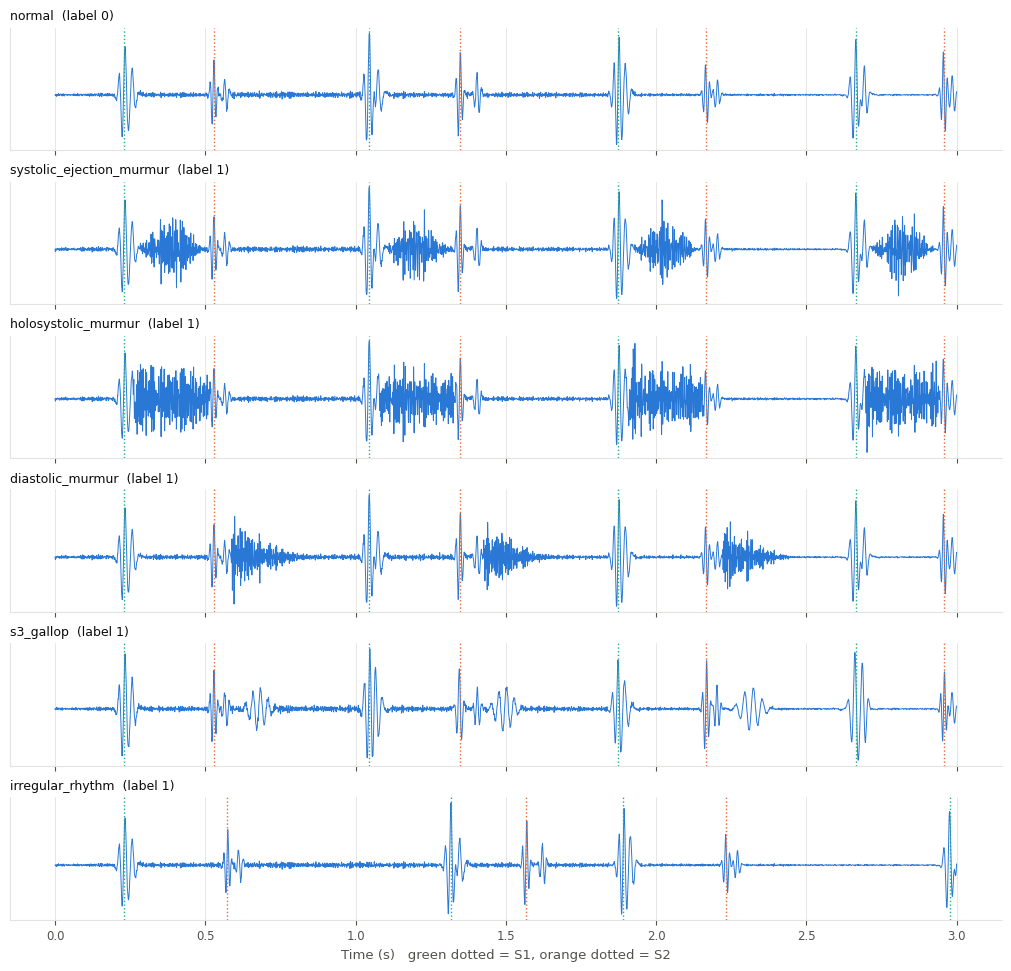

Listen: holosystolic murmur


In [19]:
# BLOCK S3 – look at and listen to the simulated heart sounds
fs = SIM["fs"]
fig, axes = plt.subplots(len(CONDITIONS), 1, figsize=(10, 1.6 * len(CONDITIONS)),
                         sharex=True, constrained_layout=True)
for ax, cond in zip(axes, CONDITIONS):
    x, info = simulate_pcg(duration_s=10, fs=fs, hr=75, condition=cond, murmur_intensity=0.6,
                           snr_db=25, seed=1)
    xf = preprocess(x, fs, CONFIG["bandpass"])
    t = np.arange(len(xf)) / fs
    m = t <= 3.0
    ax.plot(t[m], xf[m], color=SERIES[0], lw=0.7)
    for s in info["s1_times"][info["s1_times"] <= 3]:
        ax.axvline(s, color=SERIES[2], lw=1, ls=":")
    for s in info["s2_times"][info["s2_times"] <= 3]:
        ax.axvline(s, color=SERIES[1], lw=1, ls=":")
    ax.set_title(f"{cond}  (label {info['label']})", loc="left", fontsize=9)
    ax.set_yticks([])
axes[-1].set_xlabel("Time (s)   green dotted = S1, orange dotted = S2")
fig.savefig(SIM["out_dir"] / "figures" / "sim_fig1_synthetic_pcg.png", dpi=200, bbox_inches="tight")
plt.show()

x_demo, _ = simulate_pcg(duration_s=8, fs=fs, hr=75, condition="holosystolic_murmur",
                         murmur_intensity=0.6, snr_db=25, seed=1)
print("Listen: holosystolic murmur")
display(playable(x_demo, fs))

In [20]:
# BLOCK S4 – build and save the monitor model
def aggregate_window_features(rows):
    """Mean and std of window features (same format as record_features)."""
    names = list(rows[0].keys())
    W = np.array([[r[k] for k in names] for r in rows], dtype=float)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        out = {f"{k}__mean": v for k, v in zip(names, np.nanmean(W, axis=0))}
        out.update({f"{k}__std": v for k, v in zip(names, np.nanstd(W, axis=0))})
    return out


def signal_features(x, sig_cfg):
    """record_features() for a signal already in memory."""
    xp = preprocess(x, sig_cfg["fs"], sig_cfg["bandpass"])
    wins = make_windows(xp, sig_cfg["fs"], sig_cfg["window_s"], sig_cfg["hop_ratio"])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        rows = [window_features(w, sig_cfg["fs"]) for w in wins]
    return aggregate_window_features(rows)


def _simulate_and_featurise(spec, sig_cfg):
    x, info = simulate_pcg(**spec)
    f = signal_features(x, sig_cfg)
    f.update({"label": info["label"], "condition": info["condition"]})
    return f


def random_specs(n, fs, duration_s, seed, p_normal=0.5):
    rng = np.random.default_rng(seed)
    abnormal = [c for c in CONDITIONS if CONDITIONS[c] == 1]
    specs = []
    for _ in range(n):
        cond = "normal" if rng.random() < p_normal else str(rng.choice(abnormal))
        specs.append(dict(duration_s=duration_s, fs=fs, hr=float(rng.uniform(55, 110)), condition=cond,
                          murmur_intensity=float(rng.uniform(0.2, 0.9)), snr_db=float(rng.uniform(5, 30)),
                          hrv=float(rng.uniform(0.01, 0.06)), resp_rate=float(rng.uniform(10, 22)),
                          gain=float(rng.uniform(0.3, 3.0)), seed=int(rng.integers(1_000_000_000))))
    return specs


def make_synthetic_dataset(specs, sig_cfg, n_jobs=-1):
    rows = Parallel(n_jobs=n_jobs)(delayed(_simulate_and_featurise)(s, sig_cfg) for s in specs)
    df = pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan)
    df["dataset"], df["group"] = "Synthetic", [f"syn_{i}" for i in range(len(df))]
    return df


SIG_CFG = signal_config(CONFIG)
HAVE_REAL = bool(STATE.get("features"))
MONITOR_MODEL_NAME = STATE.get("best_model", {}).get(CONFIG["ablation_dataset"], "RandomForest")

n_syn = SIM["n_synthetic_train"] if HAVE_REAL else 2 * SIM["n_synthetic_train"]
t0 = time.time()
SYN_TRAIN = make_synthetic_dataset(
    random_specs(n_syn, SIM["fs"], SIM["synthetic_duration_s"], SIM["seed"]), SIG_CFG, CONFIG["n_jobs"])
print(f"Synthetic training records: {len(SYN_TRAIN)} ({time.time() - t0:.0f} s)")

COLS = STATE["cols"] if HAVE_REAL else feature_columns(SYN_TRAIN)
parts = {k: f[COLS + ["label"]] for k, f in STATE["features"].items()} if HAVE_REAL else {}
if SIM["train_with_synthetic"] or not HAVE_REAL:
    parts["Synthetic"] = SYN_TRAIN[COLS + ["label"]]
train_df = pd.concat(parts.values(), ignore_index=True)

monitor_model = CalibratedClassifierCV(make_model(MONITOR_MODEL_NAME, 0), method="sigmoid", cv=5)
monitor_model.fit(train_df[COLS].to_numpy(float), train_df["label"].to_numpy(int))
BUNDLE = {"model": monitor_model, "cols": COLS, "sig_cfg": SIG_CFG, "model_name": MONITOR_MODEL_NAME,
          "trained_on": {k: len(v) for k, v in parts.items()}}
joblib.dump(BUNDLE, SIM["out_dir"] / "heart_monitor_model.joblib")
print(f"Monitor model: calibrated {MONITOR_MODEL_NAME}, trained on {BUNDLE['trained_on']}")

Synthetic training records: 300 (39 s)
Monitor model: calibrated RandomForest, trained on {'PhysioNet2016': 400, 'Synthetic': 300}


In [21]:
# BLOCK S5 – real-time heart monitor engine
class HeartMonitor:
    """Streaming monitor: push() raw PCG samples, get one decision every hop (2.5 s)."""

    def __init__(self, bundle, sim=SIM):
        self.model, self.cols, self.sc = bundle["model"], bundle["cols"], bundle["sig_cfg"]
        self.sim = sim
        self.fs = self.sc["fs"]
        self.win = int(round(self.sc["window_s"] * self.fs))
        self.hop = max(1, int(round(self.win * self.sc["hop_ratio"])))
        self.ctx = max(int(sim["context_s"] * self.fs), self.win)
        self.reset()

    def reset(self):
        self.raw, self.inbox = np.zeros(0), np.zeros(0)
        self.n_total, self.above, self.alarm, self.p_smooth = 0, 0, False, None
        self.win_feats = collections.deque(maxlen=self.sim["n_avg_windows"])
        self.log = []

    def push(self, chunk):
        self.inbox = np.concatenate([self.inbox, np.asarray(chunk, float)])
        out = []
        while len(self.inbox) >= self.hop:
            piece, self.inbox = self.inbox[:self.hop], self.inbox[self.hop:]
            self.raw = np.concatenate([self.raw, piece])[-self.ctx:]
            self.n_total += self.hop
            if len(self.raw) >= self.win:
                out.append(self._update())
        return out

    def _update(self):
        y = preprocess(self.raw, self.fs, self.sc["bandpass"])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            wf = window_features(y[-self.win:], self.fs)
        self.win_feats.append(wf)
        feats = aggregate_window_features(list(self.win_feats))
        X = np.array([[feats.get(c, np.nan) for c in self.cols]], dtype=float)
        X[~np.isfinite(X)] = np.nan
        p = float(self.model.predict_proba(X)[0, 1])
        a = self.sim["smoothing"]
        self.p_smooth = p if self.p_smooth is None else a * self.p_smooth + (1 - a) * p
        thr = self.sim["threshold"]
        self.above = self.above + 1 if self.p_smooth >= thr else 0
        if self.above >= self.sim["alarm_consecutive"]:
            self.alarm = True
        elif self.p_smooth < thr - 0.1:                  # hysteresis: clear only when clearly normal
            self.alarm = False
        hrs = [w["rhythm|heart_rate"] for w in self.win_feats]
        hr = float(np.nanmedian(hrs)) if np.any(np.isfinite(hrs)) else np.nan
        quality = float(wf["rhythm|periodicity"])
        if len(self.win_feats) < 3:
            status = "WARM-UP"
        elif quality < 0.15:
            status = "POOR SIGNAL"
        else:
            status = "ALARM: ABNORMAL" if self.alarm else "NORMAL"
        rec = {"time_s": self.n_total / self.fs, "hr_bpm": hr, "p_abnormal": p,
               "p_smooth": self.p_smooth, "alarm": self.alarm, "quality": quality, "status": status}
        self.log.append(rec)
        return rec


def draw_dashboard(x, fs, log, truth=None, title="Heart monitor", show_s=6.0):
    """Monitor screen: live waveform, heart-rate trend, risk trend with alarms."""
    log = pd.DataFrame(log)
    t_now = log["time_s"].iloc[-1] if len(log) else len(x) / fs
    fig = plt.figure(figsize=(11, 7.2), constrained_layout=True)
    gs = fig.add_gridspec(3, 3)
    ax0 = fig.add_subplot(gs[0, :2]); axs = fig.add_subplot(gs[0, 2])
    ax1 = fig.add_subplot(gs[1, :]); ax2 = fig.add_subplot(gs[2, :], sharex=ax1)

    i1 = int(t_now * fs); i0 = max(0, i1 - int(show_s * fs))
    seg = preprocess(x[max(0, i1 - int(20 * fs)):i1], fs, CONFIG["bandpass"])[-(i1 - i0):]
    tt = np.arange(i0, i0 + len(seg)) / fs
    ax0.plot(tt, seg, color=SERIES[2], lw=0.7)
    ax0.set_title(f"Live PCG (last {show_s:g} s)", loc="left"); ax0.set_xlabel("Time (s)"); ax0.set_yticks([])

    axs.axis("off")
    if len(log):
        last = log.iloc[-1]
        col = SERIES[7] if last["alarm"] else (SERIES[2] if last["status"] == "NORMAL" else SERIES[3])
        axs.text(0.02, 0.85, f"HR  {last['hr_bpm']:.0f} bpm", fontsize=16, color=INK, transform=axs.transAxes)
        axs.text(0.02, 0.55, f"Risk  {100 * last['p_smooth']:.0f} %", fontsize=16, color=INK,
                 transform=axs.transAxes)
        axs.text(0.02, 0.22, last["status"], fontsize=13, color="white", transform=axs.transAxes,
                 bbox=dict(boxstyle="round,pad=0.4", fc=col, ec="none"))
        axs.text(0.02, 0.02, f"t = {t_now:.1f} s", fontsize=9, color=INK2, transform=axs.transAxes)

    for ax in (ax1, ax2):
        if truth is not None:
            for _, r in truth.iterrows():
                if r["label"] == 1:
                    ax.axvspan(r["start"], r["end"], color=SERIES[4], alpha=0.12, lw=0)
    if len(log):
        ax1.plot(log["time_s"], log["hr_bpm"], color=SERIES[0], marker="o", ms=3)
        if truth is not None:
            for _, r in truth.iterrows():
                ax1.hlines(r["hr"], r["start"], r["end"], color=INK2, ls="--", lw=1)
        ax2.plot(log["time_s"], log["p_abnormal"], color="#b9b8b2", lw=1, label="P(abnormal) per update")
        ax2.plot(log["time_s"], log["p_smooth"], color=SERIES[1], lw=2, label="Smoothed risk")
        al = log[log["alarm"]]
        ax2.scatter(al["time_s"], np.full(len(al), 1.04), marker="|", s=80, color=SERIES[7], label="Alarm")
    ax1.set_ylabel("Heart rate (bpm)"); ax1.set_title("Heart-rate trend (dashed = true HR)", loc="left")
    ax2.axhline(SIM["threshold"], color=INK2, ls=":", lw=1)
    ax2.set_ylim(-0.02, 1.1); ax2.set_ylabel("P(abnormal)"); ax2.set_xlabel("Time (s)")
    ax2.set_title("Abnormality risk (pink = truly abnormal period)", loc="left")
    ax2.legend(loc="upper left", bbox_to_anchor=(0, -0.3), ncol=3)
    xmax = (truth["end"].max() if truth is not None else len(x) / fs)
    ax1.set_xlim(0, xmax)
    fig.suptitle(title, x=0.01, ha="left", color=INK)
    return fig


def run_session(x, fs, bundle, truth=None, live=False, redraw_every=4, title="Heart monitor"):
    """Stream a signal through a fresh monitor, chunk by chunk, as a real device would."""
    mon = HeartMonitor(bundle)
    for k, start in enumerate(range(0, len(x), mon.hop)):
        mon.push(x[start:start + mon.hop])
        if live and mon.log and k % redraw_every == 0:
            clear_output(wait=True)
            draw_dashboard(x, fs, mon.log, truth, title); plt.show()
    if live:
        clear_output(wait=True)
    fig = draw_dashboard(x, fs, mon.log, truth, title)
    return pd.DataFrame(mon.log), fig


def session_metrics(log, truth, settle_s=15.0):
    """Per-segment accuracy, alarm latency and false-alarm rate (ignoring settle time after changes)."""
    rows = []
    for _, r in truth.iterrows():
        seg = log[(log["time_s"] > r["start"] + settle_s) & (log["time_s"] <= r["end"])]
        seg_all = log[(log["time_s"] > r["start"]) & (log["time_s"] <= r["end"])]
        alarm_t = seg_all.loc[seg_all["alarm"], "time_s"]
        rows.append({"segment": f"{r['start']:.0f}-{r['end']:.0f} s", "condition": r["condition"],
                     "true label": r["label"],
                     "updates correct %": 100 * np.mean(seg["alarm"].astype(int) == r["label"]) if len(seg) else np.nan,
                     "alarm latency (s)": (alarm_t.iloc[0] - r["start"]) if (r["label"] == 1 and len(alarm_t)) else np.nan,
                     "true HR": r["hr"], "estimated HR (median)": seg["hr_bpm"].median()})
    return pd.DataFrame(rows)

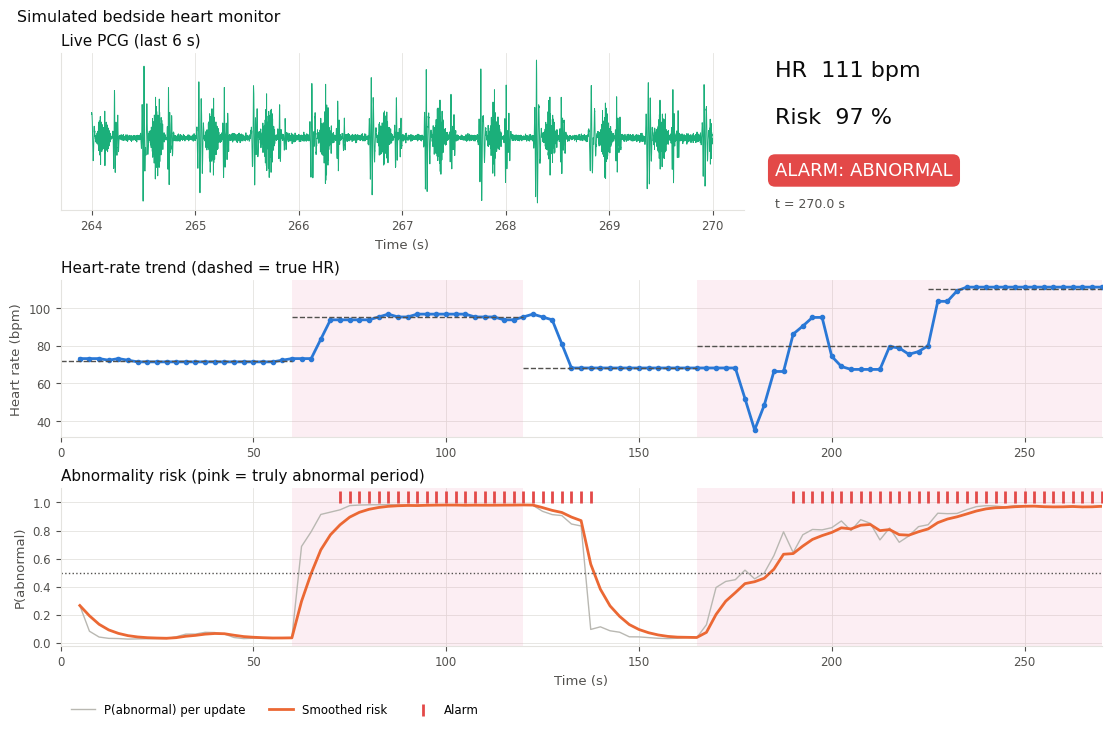

,segment,condition,true label,updates correct %,alarm latency (s),true HR,estimated HR (median)
0,0-60 s,normal,0,100.00,NaN,72,71.43
1,60-120 s,holosystolic_murmur,1,100.00,12.5,95,95.26
2,120-165 s,normal,0,91.67,NaN,68,68.18
3,165-225 s,irregular_rhythm,1,83.33,25.0,80,74.91
4,225-270 s,systolic_ejection_murmur,1,100.00,2.5,110,111.11


In [22]:
# BLOCK S6 – simulate a monitoring session (patient whose condition changes)
SCENARIO = [
    dict(duration_s=60, hr=72, condition="normal", snr_db=25),
    dict(duration_s=60, hr=95, condition="holosystolic_murmur", murmur_intensity=0.6, snr_db=20),
    dict(duration_s=45, hr=68, condition="normal", snr_db=8),          # noisy but normal: false alarms?
    dict(duration_s=60, hr=80, condition="irregular_rhythm", snr_db=20),
    dict(duration_s=45, hr=110, condition="systolic_ejection_murmur", murmur_intensity=0.5, snr_db=15),
]
x_scn, truth_scn = simulate_scenario(SCENARIO, fs=SIM["fs"], seed=SIM["seed"])
print(f"Scenario: {len(x_scn) / SIM['fs']:.0f} s of simulated PCG")
display(truth_scn)

LIVE = True          # True = animated monitor screen in the notebook; False = only the final screen
log_scn, fig_scn = run_session(x_scn, SIM["fs"], BUNDLE, truth_scn, live=LIVE,
                               title="Simulated bedside heart monitor")
fig_scn.savefig(SIM["out_dir"] / "figures" / "sim_fig2_monitor_session.png", dpi=200, bbox_inches="tight")
plt.show()

scn_metrics = session_metrics(log_scn, truth_scn)
scn_metrics.to_csv(SIM["out_dir"] / "tables" / "sim_session_metrics.csv", index=False)
log_scn.to_csv(SIM["out_dir"] / "tables" / "sim_session_log.csv", index=False)
display(scn_metrics.round(2))

In [23]:
# BLOCK S7 – interactive simulator (sliders)
w_cond = widgets.Dropdown(options=list(CONDITIONS), value="normal", description="Condition")
w_hr = widgets.IntSlider(value=75, min=40, max=160, step=1, description="Heart rate")
w_int = widgets.FloatSlider(value=0.5, min=0.0, max=1.0, step=0.05, description="Murmur level")
w_snr = widgets.FloatSlider(value=20, min=0, max=40, step=1, description="SNR (dB)")
w_dur = widgets.IntSlider(value=30, min=10, max=90, step=5, description="Duration (s)")
w_seed = widgets.IntText(value=0, description="Seed")
btn = widgets.Button(description="Run monitor", button_style="primary")
out = widgets.Output()


def _on_run(_):
    with out:
        clear_output(wait=True)
        x, info = simulate_pcg(duration_s=w_dur.value, fs=SIM["fs"], hr=w_hr.value,
                               condition=w_cond.value, murmur_intensity=w_int.value,
                               snr_db=w_snr.value, seed=w_seed.value)
        truth = pd.DataFrame([{"start": 0, "end": w_dur.value, "condition": info["condition"],
                               "label": info["label"], "hr": info["hr"]}])
        log, fig = run_session(x, SIM["fs"], BUNDLE, truth, title=f"Simulated: {w_cond.value}")
        plt.show()
        last = log.iloc[-1]
        verdict = "ABNORMAL" if last["alarm"] else "NORMAL"
        truth_txt = "abnormal" if info["label"] else "normal"
        print(f"Monitor verdict: {verdict} (risk {last['p_smooth']:.2f}) | truth: {truth_txt} | "
              f"HR estimated {last['hr_bpm']:.0f} vs true {w_hr.value} bpm")
        display(playable(x, SIM["fs"]))


btn.on_click(_on_run)
display(widgets.VBox([widgets.HBox([w_cond, w_hr, w_int]), widgets.HBox([w_snr, w_dur, w_seed]), btn, out]))

Held-out synthetic test: {'MAcc': 0.985, 'Se': 0.979, 'Sp': 0.99, 'F1': 0.984, 'AUC': np.float64(1.0), 'MCC': 0.97}


,condition,n,% classified abnormal
0,diastolic_murmur,21,100.0
1,holosystolic_murmur,22,100.0
2,irregular_rhythm,18,100.0
3,normal,103,1.0
4,s3_gallop,22,95.5
5,systolic_ejection_murmur,14,92.9


Robustness grid: 432 simulated recordings (52 s)


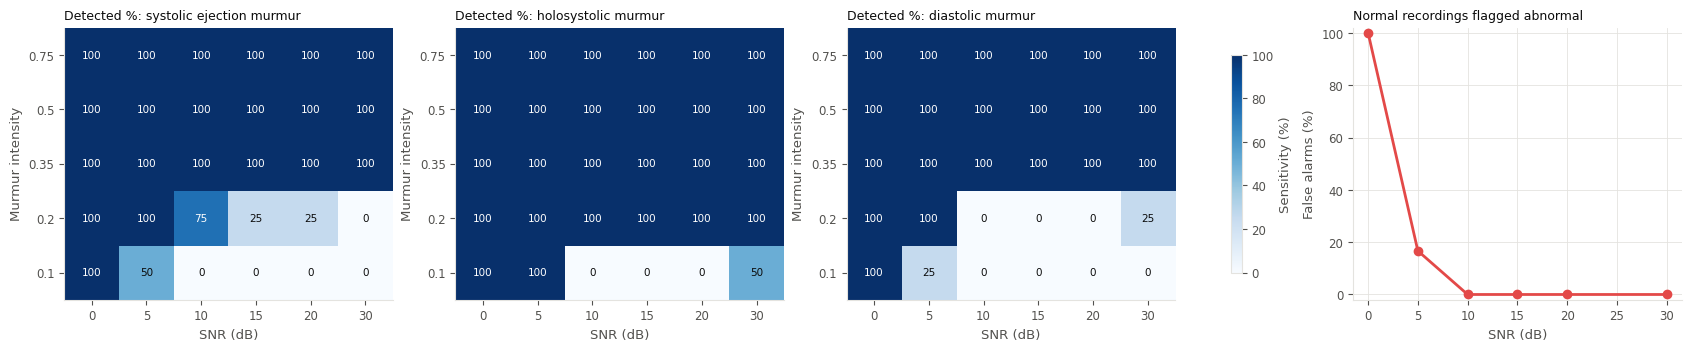

Heart-rate estimation: MAE = 0.5 bpm, within 5 bpm: 100%


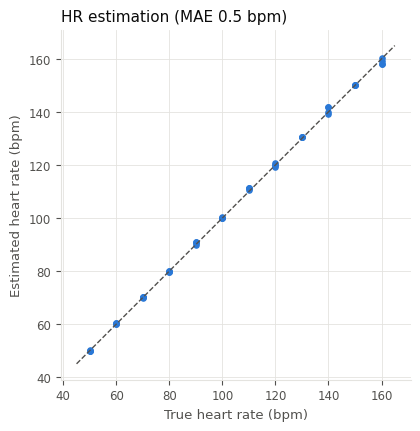

In [24]:
# BLOCK S8 – simulation experiments for the paper
def predict_records(df):
    return BUNDLE["model"].predict_proba(df[COLS].to_numpy(float))[:, 1]

# (a) Held-out synthetic test set (new random seed, never used in training)
SYN_TEST = make_synthetic_dataset(random_specs(200, SIM["fs"], SIM["synthetic_duration_s"], SIM["seed"] + 999),
                                  SIG_CFG, CONFIG["n_jobs"])
p = predict_records(SYN_TEST)
m_all = compute_metrics(SYN_TEST["label"], (p >= 0.5).astype(int), p)
per_cond = SYN_TEST.assign(pred=(p >= 0.5).astype(int)).groupby("condition")["pred"].agg(
    ["size", "mean"]).rename(columns={"size": "n", "mean": "% classified abnormal"}).reset_index()
per_cond["% classified abnormal"] *= 100
print("Held-out synthetic test:", {k: round(v, 3) for k, v in m_all.items()})
display(per_cond.round(1))
per_cond.to_csv(SIM["out_dir"] / "tables" / "sim_synthetic_test_by_condition.csv", index=False)

# (b) Robustness: detection rate vs SNR x murmur intensity, false-alarm rate vs SNR
SNRS = [0, 5, 10, 15, 20, 30]
INTENSITIES = [0.1, 0.2, 0.35, 0.5, 0.75]
MURMURS = ["systolic_ejection_murmur", "holosystolic_murmur", "diastolic_murmur"]
rng = np.random.default_rng(SIM["seed"] + 7)
grid_specs = []
for cond in MURMURS:
    for snr in SNRS:
        for inten in INTENSITIES:
            for _ in range(SIM["grid_reps"]):
                grid_specs.append(dict(duration_s=20, fs=SIM["fs"], hr=float(rng.uniform(60, 100)),
                                       condition=cond, murmur_intensity=inten, snr_db=snr,
                                       seed=int(rng.integers(1e9))))
for snr in SNRS:
    for _ in range(3 * SIM["grid_reps"]):
        grid_specs.append(dict(duration_s=20, fs=SIM["fs"], hr=float(rng.uniform(60, 100)),
                               condition="normal", murmur_intensity=0.0, snr_db=snr,
                               seed=int(rng.integers(1e9))))
t0 = time.time()
GRID = make_synthetic_dataset(grid_specs, SIG_CFG, CONFIG["n_jobs"])
GRID["snr_db"] = [s["snr_db"] for s in grid_specs]
GRID["intensity"] = [s["murmur_intensity"] for s in grid_specs]
GRID["pred"] = (predict_records(GRID) >= 0.5).astype(int)
print(f"Robustness grid: {len(GRID)} simulated recordings ({time.time() - t0:.0f} s)")

fig, axes = plt.subplots(1, len(MURMURS) + 1, figsize=(4.2 * (len(MURMURS) + 1), 3.4),
                         constrained_layout=True)
for ax, cond in zip(axes, MURMURS):
    tab = GRID[GRID.condition == cond].pivot_table(index="intensity", columns="snr_db", values="pred") * 100
    im = ax.imshow(tab.values, origin="lower", cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(tab.columns))); ax.set_xticklabels(tab.columns)
    ax.set_yticks(range(len(tab.index))); ax.set_yticklabels(tab.index)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.5,
                    color="white" if v > 60 else INK)
    ax.set_xlabel("SNR (dB)"); ax.set_ylabel("Murmur intensity"); ax.grid(False)
    ax.set_title(f"Detected %: {cond.replace('_', ' ')}", loc="left", fontsize=9)
fa = GRID[GRID.condition == "normal"].groupby("snr_db")["pred"].mean() * 100
axes[-1].plot(fa.index, fa.values, marker="o", color=SERIES[7])
axes[-1].set_ylim(-2, 102); axes[-1].set_xlabel("SNR (dB)"); axes[-1].set_ylabel("False alarms (%)")
axes[-1].set_title("Normal recordings flagged abnormal", loc="left", fontsize=9)
fig.colorbar(im, ax=axes[:len(MURMURS)], shrink=0.8, label="Sensitivity (%)")
fig.savefig(SIM["out_dir"] / "figures" / "sim_fig3_robustness.png", dpi=200, bbox_inches="tight")
plt.show()
GRID.groupby(["condition", "snr_db", "intensity"])["pred"].mean().mul(100).rename("% flagged abnormal") \
    .reset_index().to_csv(SIM["out_dir"] / "tables" / "sim_robustness_grid.csv", index=False)

# (c) Heart-rate estimation accuracy of the envelope-autocorrelation method
hr_specs, hr_true = [], []
for hr in range(50, 161, 10):
    for r in range(SIM["grid_reps"]):
        hr_specs.append(dict(duration_s=20, fs=SIM["fs"], hr=float(hr), condition="normal", snr_db=20,
                             seed=1000 * hr + r))
        hr_true.append(hr)
HRDF = make_synthetic_dataset(hr_specs, SIG_CFG, CONFIG["n_jobs"])
HRDF["true_hr"] = hr_true
HRDF["est_hr"] = HRDF["rhythm|heart_rate__mean"]
err = (HRDF["est_hr"] - HRDF["true_hr"]).abs()
print(f"Heart-rate estimation: MAE = {err.mean():.1f} bpm, within 5 bpm: {100 * (err <= 5).mean():.0f}%")
fig, ax = plt.subplots(figsize=(4.6, 4.2), constrained_layout=True)
ax.scatter(HRDF["true_hr"], HRDF["est_hr"], s=14, color=SERIES[0])
ax.plot([45, 165], [45, 165], color=INK2, ls="--", lw=1)
ax.set_xlabel("True heart rate (bpm)"); ax.set_ylabel("Estimated heart rate (bpm)")
ax.set_title(f"HR estimation (MAE {err.mean():.1f} bpm)", loc="left"); ax.set_aspect("equal")
fig.savefig(SIM["out_dir"] / "figures" / "sim_fig4_hr_accuracy.png", dpi=200, bbox_inches="tight")
plt.show()
HRDF[["true_hr", "est_hr"]].to_csv(SIM["out_dir"] / "tables" / "sim_hr_accuracy.csv", index=False)

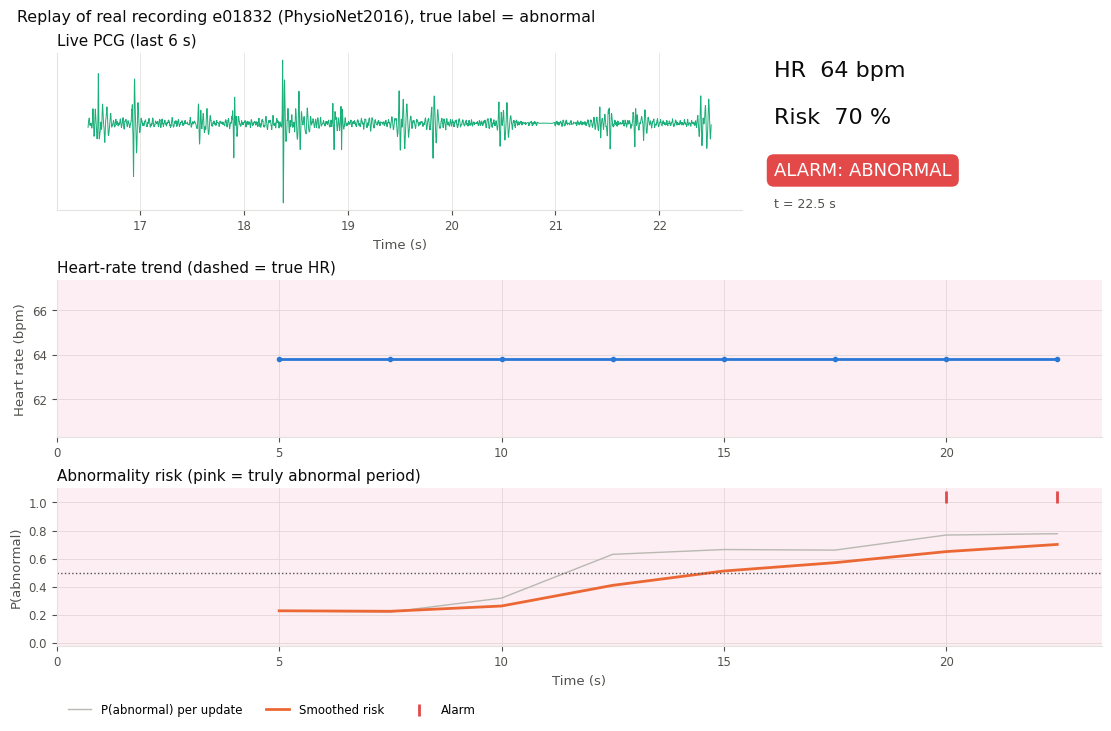

Final monitor status: ALARM: ABNORMAL | risk 0.70


In [25]:
# BLOCK S9 – replay a real recording through the monitor
if not HAVE_REAL:
    print("No real recordings loaded, so the real-data replay is skipped.")
else:
    REPLAY_DATASET = "PhysioNet2016" if "PhysioNet2016" in STATE["index"] else next(iter(STATE["index"]))
    REPLAY_LABEL = 1       # 1 = pick an abnormal recording, 0 = a normal one
    rec = STATE["index"][REPLAY_DATASET].query("label == @REPLAY_LABEL").sample(1, random_state=3).iloc[0]
    x_real = load_pcg(rec["path"], SIM["fs"])
    truth_real = pd.DataFrame([{"start": 0, "end": len(x_real) / SIM["fs"],
                                "condition": "abnormal" if rec["label"] else "normal",
                                "label": rec["label"], "hr": np.nan}])
    log_real, fig_real = run_session(x_real, SIM["fs"], BUNDLE, truth_real, live=False,
                                     title=f"Replay of real recording {rec['record']} ({REPLAY_DATASET}), "
                                           f"true label = {'abnormal' if rec['label'] else 'normal'}")
    fig_real.savefig(SIM["out_dir"] / "figures" / "sim_fig5_real_replay.png", dpi=200, bbox_inches="tight")
    plt.show()
    if len(log_real):
        print("Final monitor status:", log_real.iloc[-1]["status"],
              f"| risk {log_real.iloc[-1]['p_smooth']:.2f}")
    else:
        print("Recording shorter than one analysis window; no decision made.")
    display(playable(x_real, SIM["fs"]))

## Optional: paper experiments 1–3 on the real data
Classifier comparison, ablation and statistics (PhysioNet 2016 only here). Set `RUN_EXPERIMENTS = True` to run them
(they take longer than the simulation).

In [28]:
RUN_EXPERIMENTS = True

if RUN_EXPERIMENTS and STATE.get("features"):
    display(step_classifier_comparison(CONFIG, STATE))
    display(step_classifier_statistics(CONFIG, STATE))
    display(step_ablation(CONFIG, STATE))
    print(step_summary(CONFIG, STATE))

,dataset,model,MAcc,MAcc 95% CI,MAcc sd,Se,Sp,F1,AUC,MCC
0,PhysioNet2016,LogReg,0.804,"[0.743, 0.865]",0.049,0.704,0.905,0.637,0.884,0.570
1,PhysioNet2016,LDA,0.862,"[0.808, 0.916]",0.044,0.840,0.884,0.687,0.900,0.635
2,PhysioNet2016,SVM-RBF,0.785,"[0.709, 0.862]",0.062,0.640,0.931,0.638,0.927,0.571
3,PhysioNet2016,RandomForest,0.701,"[0.613, 0.790]",0.071,0.438,0.964,0.527,0.926,0.492
4,PhysioNet2016,GradBoost,0.730,"[0.658, 0.802]",0.058,0.525,0.935,0.550,0.924,0.489


,dataset,best,vs,ΔMAcc,Wilcoxon p,corrected t p,Cohen dz,rank diff,Nemenyi CD,Wilcoxon p (Holm),corrected t p (Holm),Friedman χ²,Friedman p
0,PhysioNet2016,LDA,LogReg,0.0580,0.0625,0.0036,4.0990,1.4,2.728,0.25,0.0145,16.202,0.0028
1,PhysioNet2016,LDA,SVM-RBF,0.0767,0.0625,0.1123,1.3613,1.9,2.728,0.25,0.1256,16.202,0.0028
2,PhysioNet2016,LDA,RandomForest,0.1609,0.0625,0.0237,2.3835,3.4,2.728,0.25,0.0712,16.202,0.0028
3,PhysioNet2016,LDA,GradBoost,0.1324,0.0625,0.0628,1.7157,3.3,2.728,0.25,0.1256,16.202,0.0028


Ablation on PhysioNet2016 with LDA
  no filter: 400 records, 190 features, 0 unreadable, 93 s
  window 2.5s: 400 records, 190 features, 0 unreadable, 77 s
  window 10s: 400 records, 190 features, 0 unreadable, 30 s


,configuration,MAcc,MAcc 95% CI,Se,Sp,AUC,ΔMAcc,Δ 95% CI,Wilcoxon p,corrected t p,Cohen dz,Wilcoxon p (Holm),corrected t p (Holm),significant
0,Full model,0.8621,"[0.808, 0.916]",0.8401,0.8841,0.8997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
1,− mfcc features,0.8304,"[0.788, 0.873]",0.7917,0.8690,0.8888,-0.0317,"[-0.065, 0.002]",0.0625,0.1526,-1.1829,0.5625,1.0,False
2,− spectral features,0.8502,"[0.793, 0.908]",0.8165,0.8838,0.9022,-0.0119,"[-0.056, 0.032]",0.8750,0.6433,-0.3355,1.0000,1.0,False
3,− wavelet features,0.8680,"[0.817, 0.919]",0.8583,0.8778,0.9023,0.0059,"[-0.027, 0.039]",0.8750,0.7536,0.2256,1.0000,1.0,False
4,− temporal features,0.8494,"[0.785, 0.914]",0.8150,0.8838,0.8933,-0.0127,"[-0.040, 0.015]",0.3750,0.4474,-0.5646,1.0000,1.0,False
5,− rhythm features,0.8188,"[0.758, 0.880]",0.7748,0.8628,0.9011,-0.0433,"[-0.093, 0.007]",0.1250,0.1839,-1.0763,1.0000,1.0,False
6,MFCC only (audio baseline),0.8123,"[0.728, 0.897]",0.7748,0.8498,0.8874,-0.0498,"[-0.127, 0.027]",0.1875,0.2956,-0.8065,1.0000,1.0,False
7,No band-pass filter,0.8571,"[0.760, 0.954]",0.8134,0.9007,0.9210,-0.0050,"[-0.062, 0.052]",1.0000,0.8792,-0.1086,1.0000,1.0,False
8,Window 2.5 s (vs 5 s),0.8574,"[0.785, 0.930]",0.8348,0.8801,0.8968,-0.0046,"[-0.082, 0.072]",0.6250,0.9166,-0.0748,1.0000,1.0,False
9,Window 10 s (vs 5 s),0.8152,"[0.732, 0.898]",0.7597,0.8707,0.9027,-0.0469,"[-0.130, 0.036]",0.1875,0.3534,-0.7037,1.0000,1.0,False


# Results summary

Settings: fs = 2000 Hz, band-pass = (25.0, 400.0), window = 5.0 s, 5-fold stratified group CV × 1 seeds (QUICK MODE: subset of data, not for the paper)

## Datasets

| dataset       |   recordings |   subjects/groups |   abnormal |   normal |   abnormal % | sites/locations   |
|:--------------|-------------:|------------------:|-----------:|---------:|-------------:|:------------------|
| PhysioNet2016 |          400 |               400 |         67 |      333 |         16.8 | a, b, c, d, e, f  |

## Experiment 1: classifier comparison

| dataset       | model        |   MAcc | MAcc 95% CI    |   MAcc sd |     Se |     Sp |     F1 |    AUC |    MCC |
|:--------------|:-------------|-------:|:---------------|----------:|-------:|-------:|-------:|-------:|-------:|
| PhysioNet2016 | LogReg       | 0.8041 | [0.743, 0.865] |    0.049  | 0.7035 | 0.9046 | 0.6369 | 0.8836 | 0.5697 |
| PhysioNet2016 | LDA          | 0.8621 | [0.808, 0.916] |    0.0435 | 0.8401 | 0.8841 | 0

In [27]:
# Download all results (figures, tables, trained monitor model) as a zip
shutil.make_archive("heart_monitor_results", "zip", CONFIG["results_dir"])
try:
    from google.colab import files
    files.download("heart_monitor_results.zip")
except ImportError:
    print("Saved heart_monitor_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>